<a href="https://colab.research.google.com/github/EmanAdil122/federated-eeg-working-memory/blob/main/notebooks/EEG_Preprocessing_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
%cd /content
!git clone https://github.com/EmanAdil122/federated-eeg-working-memory.git
%cd /content/federated-eeg-working-memory
!ls

/content
Cloning into 'federated-eeg-working-memory'...
remote: Enumerating objects: 127, done.
remote: Counting objects: 100% (127/127), done.
remote: Compressing objects: 100% (101/101), done.
remote: Total 127 (delta 28), reused 118 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (127/127), 5.03 MiB | 11.32 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/federated-eeg-working-memory
data_scripts  notebooks  README.md  requirements.txt
documents     paper	 reports    src


In [ ]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 97.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 109.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 113.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.9/947.9 kB 45.3 MB/s  0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [jupyter]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:
%cd /content/federated-eeg-working-memory

import mne
import numpy
import pandas

print("EEG setup OK")

/content/federated-eeg-working-memory
EEG setup OK


In [3]:
from pathlib import Path
from urllib.parse import quote
import xml.etree.ElementTree as ET

import requests

bucket = "https://s3.amazonaws.com/openneuro.org"
data_dir = Path("/content/federated-eeg-working-memory/data")
participants = ["sub-001", "sub-002"]

with requests.Session() as session:
    for participant in participants:
        print(f"\nProcessing {participant}", flush=True)

        prefix = f"ds003655/{participant}/eeg/"
        params = {"list-type": "2", "prefix": prefix}
        files = []

        # Read all pages of the file listing.
        while True:
            listing = session.get(bucket, params=params, timeout=60)
            listing.raise_for_status()
            root = ET.fromstring(listing.content)

            for item in root.findall("{*}Contents"):
                key = item.findtext("{*}Key")
                size = int(item.findtext("{*}Size", default="0"))

                if key and not key.endswith("/"):
                    files.append((key, size))

            token = root.findtext("{*}NextContinuationToken")
            if not token:
                break
            params["continuation-token"] = token

        if not files:
            raise RuntimeError(f"No EEG files found for {participant}")

        for key, expected_size in files:
            relative_path = key.removeprefix("ds003655/")
            target = data_dir / relative_path
            target.parent.mkdir(parents=True, exist_ok=True)

            if target.exists() and target.stat().st_size == expected_size:
                print(f"Already downloaded: {target.name}", flush=True)
                continue

            temporary = target.with_suffix(target.suffix + ".part")
            url = f"{bucket}/{quote(key, safe='/')}"

            print(f"Downloading: {target.name}", flush=True)

            with session.get(url, stream=True, timeout=120) as response:
                response.raise_for_status()

                with temporary.open("wb") as output:
                    for chunk in response.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if chunk:
                            output.write(chunk)

            if temporary.stat().st_size != expected_size:
                raise RuntimeError(
                    f"Incomplete download: {target.name}. Run this cell again."
                )

            temporary.replace(target)

        print(f"{participant}: {len(files)} files ready", flush=True)

print("\nBoth participants downloaded. Ready for file validation.")


Processing sub-001
Downloading: sub-001_task-VerbalWorkingMemory_channels.tsv
Downloading: sub-001_task-VerbalWorkingMemory_coordsystem.json
Downloading: sub-001_task-VerbalWorkingMemory_eeg.fdt
Downloading: sub-001_task-VerbalWorkingMemory_eeg.json
Downloading: sub-001_task-VerbalWorkingMemory_eeg.set
Downloading: sub-001_task-VerbalWorkingMemory_electrodes.tsv
Downloading: sub-001_task-VerbalWorkingMemory_events.json
Downloading: sub-001_task-VerbalWorkingMemory_events.tsv
sub-001: 8 files ready

Processing sub-002
Downloading: sub-002_task-VerbalWorkingMemory_channels.tsv
Downloading: sub-002_task-VerbalWorkingMemory_coordsystem.json
Downloading: sub-002_task-VerbalWorkingMemory_eeg.fdt
Downloading: sub-002_task-VerbalWorkingMemory_eeg.json
Downloading: sub-002_task-VerbalWorkingMemory_eeg.set
Downloading: sub-002_task-VerbalWorkingMemory_electrodes.tsv
Downloading: sub-002_task-VerbalWorkingMemory_events.json
Downloading: sub-002_task-VerbalWorkingMemory_events.tsv
sub-002: 8 file

In [ ]:
%cd /content/federated-eeg-working-memory
!python data_scripts/01_check_downloads.py

/content/federated-eeg-working-memory

========== DOWNLOAD INVENTORY ==========
participant  folder_exists  file_count  _eeg.set  _eeg.fdt  _events.tsv  _channels.tsv  _eeg.json  complete  size_MB
    sub-001           True           8      True      True         True           True       True      True   135.45
    sub-002           True           8      True      True         True           True       True      True   133.60

Participants found: 2
Complete participant folders: 2
Incomplete participant folders: 0
Report saved to: /content/federated-eeg-working-memory/reports/download_inventory.csv


In [ ]:
!python data_scripts/02_validate_data.py


Checking sub-001...
Channels: 21
Sampling frequency: 500.0 Hz
Duration: 51.28 minutes
Event rows: 849
Exact duplicate event rows: 0
Onsets outside recording: 0

Checking sub-002...
Channels: 21
Sampling frequency: 500.0 Hz
Duration: 50.58 minutes
Event rows: 843
Exact duplicate event rows: 0
Onsets outside recording: 0

========== VALIDATION COMPLETE ==========
Participant summaries: 2
Errors: 0
Reports saved in: /content/federated-eeg-working-memory/reports


In [ ]:
!python data_scripts/03_inspect_trials.py


PARTICIPANT: sub-001

Event types and counts:
trial_type
start of the trial                                                120
presentation of the task instruction                              120
start of the baseline period: Manipulation with 6 letters (6M)     20
delay period: 6M                                                   20
encoding: 6M                                                       20
probe: 6M                                                          20
encoding: 7R                                                       20
probe: 7M                                                          20
start of the baseline period: Retention of 7 letters (7R)          20
probe: 7R                                                          20
delay period: 7R                                                   20
probe: 6R                                                          20
delay period: 6R                                                   20
encoding: 6R                    

In [ ]:
!python data_scripts/04_build_trial_table.py


sub-001: 120 trial rows

Trials per condition:
condition
6M    20
7R    20
6R    20
5M    20
5R    20
7M    20
Name: count, dtype: int64

Quality status:
trial_quality
passed    114
check       6
Name: count, dtype: int64
Total response markers: 124

sub-002: 120 trial rows

Trials per condition:
condition
6M    20
7M    20
7R    20
6R    20
5M    20
5R    20
Name: count, dtype: int64

Quality status:
trial_quality
passed    118
check       2
Name: count, dtype: int64
Total response markers: 120

Saved: /content/federated-eeg-working-memory/reports/trial_table.csv
Saved: /content/federated-eeg-working-memory/reports/trial_quality_issues.csv

Total trial rows: 240
Trials requiring review: 8


In [ ]:
import pandas as pd
from IPython.display import display

issues = pd.read_csv("reports/trial_quality_issues.csv")

display(issues[["participant_id", "trial_number", "condition", "issue","event_labels"]])

,participant_id,trial_number,condition,issue,event_labels
0,sub-001,26,7R,missing_response,start of the trial | start of the baseline per...
1,sub-001,27,7R,multiple_responses,start of the trial | start of the baseline per...
2,sub-001,44,6R,multiple_responses,start of the trial | Response: 6R: correct | s...
3,sub-001,92,5R,multiple_responses,start of the trial | start of the baseline per...
4,sub-001,104,7M,multiple_responses,start of the trial | start of the baseline per...
5,sub-001,112,7M,multiple_responses,start of the trial | start of the baseline per...
6,sub-002,70,6R,missing_response,start of the trial | start of the baseline per...
7,sub-002,71,6R,multiple_responses,start of the trial | start of the baseline per...


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

for participant, group in issues.groupby("participant_id"):
    event_file = next(
        Path(f"data/{participant}/eeg").glob("*_events.tsv")
    )
    events = pd.read_csv(event_file, sep="\t")
    events = events.sort_values("onset").reset_index(drop=True)

    starts = events.index[
        events["trial_type"].str.strip().eq("start of the trial")
    ].tolist()

    for trial_number in group["trial_number"].unique():
        position = int(trial_number) - 1
        start = starts[position]
        stop = (
            starts[position + 1]
            if position + 1 < len(starts)
            else len(events)
        )

        trial = events.iloc[start:stop]
        probes = trial[
            trial["trial_type"].str.startswith("probe:", na=False)
        ]

        print(f"\n{participant} — Trial {trial_number}")

        if probes.empty:
            print("Probe marker missing")
            continue

        probe_time = probes.iloc[0]["onset"]
        next_start = (
            events.iloc[stop]["onset"]
            if stop < len(events)
            else events["onset"].max()
        )

        nearby = events.loc[
            events["onset"].between(
                trial.iloc[0]["onset"], next_start + 3
            ),
            ["onset", "trial_type"]
        ].copy()

        nearby["seconds_from_probe"] = (
            nearby["onset"] - probe_time
        ).round(3)

        display(nearby.reset_index(drop=True))


sub-001 — Trial 26


,onset,trial_type,seconds_from_probe
0,1138.700,start of the trial,-13.900
1,1139.000,start of the baseline period: Retention of 7 l...,-13.600
2,1142.200,presentation of the task instruction,-10.400
3,1142.800,encoding: 7R,-9.800
4,1146.000,delay period: 7R,-6.600
5,1152.600,probe: 7R,0.000
6,1158.800,start of the trial,6.200
7,1159.100,start of the baseline period: Retention of 7 l...,6.500
8,1159.556,Response: 7R: correct,6.956



sub-001 — Trial 27


,onset,trial_type,seconds_from_probe
0,1158.800,start of the trial,-13.900
1,1159.100,start of the baseline period: Retention of 7 l...,-13.600
2,1159.556,Response: 7R: correct,-13.144
3,1162.300,presentation of the task instruction,-10.400
4,1162.900,encoding: 7R,-9.800
5,1166.100,delay period: 7R,-6.600
6,1172.700,probe: 7R,0.000
7,1174.110,Response: 7R: correct,1.410
8,1179.100,start of the trial,6.400
9,1179.500,start of the baseline period: Retention of 7 l...,6.800



sub-001 — Trial 44


,onset,trial_type,seconds_from_probe
0,1505.200,start of the trial,-14.000
1,1505.208,Response: 6R: correct,-13.992
2,1505.600,start of the baseline period: Retention of 6 l...,-13.600
3,1508.700,presentation of the task instruction,-10.500
4,1509.400,encoding: 6R,-9.800
5,1512.500,delay period: 6R,-6.700
6,1519.200,probe: 6R,0.000
7,1522.666,Response: 6R: correct,3.466
8,1525.700,start of the trial,6.500
9,1526.000,start of the baseline period: Retention of 6 l...,6.800


... (6 outputs left out)


sub-002 — Trial 70


,onset,trial_type,seconds_from_probe
0,1944.600,start of the trial,-14.000
1,1945.000,start of the baseline period: Retention of 6 l...,-13.600
2,1948.100,presentation of the task instruction,-10.500
3,1948.800,encoding: 6R,-9.800
4,1951.900,delay period: 6R,-6.700
5,1958.600,probe: 6R,0.000
6,1965.000,start of the trial,6.400
7,1965.400,start of the baseline period: Retention of 6 l...,6.800
8,1965.774,Response: 6R: error,7.174



sub-002 — Trial 71


,onset,trial_type,seconds_from_probe
0,1965.000,start of the trial,-14.000
1,1965.400,start of the baseline period: Retention of 6 l...,-13.600
2,1965.774,Response: 6R: error,-13.226
3,1968.500,presentation of the task instruction,-10.500
4,1969.200,encoding: 6R,-9.800
5,1972.300,delay period: 6R,-6.700
6,1979.000,probe: 6R,0.000
7,1982.160,Response: 6R: correct,3.160
8,1985.400,start of the trial,6.400
9,1985.800,start of the baseline period: Retention of 6 l...,6.800


In [ ]:
import json
from pathlib import Path
from IPython.display import display, JSON

for participant in ["sub-001", "sub-002"]:
    metadata_file = next(
        Path(f"data/{participant}/eeg").glob("*_events.json")
    )

    print(f"\n{participant} — Event metadata")

    with metadata_file.open(encoding="utf-8") as file:
        metadata = json.load(file)

    display(JSON(metadata, expanded=True))


sub-001 — Event metadata


<IPython.core.display.JSON object>


sub-002 — Event metadata


<IPython.core.display.JSON object>

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

event_file = next(
    Path("data/sub-001/eeg").glob("*_events.tsv")
)
events = pd.read_csv(event_file, sep="\t")
events = events.sort_values("onset").reset_index(drop=True)

starts = events.index[
    events["trial_type"].str.strip().eq("start of the trial")
].tolist()

# Trials 43 and 44, ending before trial 45.
selected = events.iloc[starts[42]:starts[44]].copy()

probe_43 = events.iloc[starts[42]:starts[43]]
probe_43 = probe_43.loc[
    probe_43["trial_type"].str.startswith("probe:", na=False),
    "onset"
].iloc[0]

selected["seconds_from_trial43_probe"] = (
    selected["onset"] - probe_43
).round(3)

columns = ["onset", "trial_type", "seconds_from_trial43_probe"]
if "value" in selected.columns:
    columns.append("value")

with pd.option_context("display.max_colwidth", None):
    display(selected[columns].reset_index(drop=True))

,onset,trial_type,seconds_from_trial43_probe,value
0,1484.800,start of the trial,-14.000,500
1,1485.100,start of the baseline period: Retention of 6 letters (6R),-13.700,160
2,1488.300,presentation of the task instruction,-10.500,4
3,1488.900,encoding: 6R,-9.900,260
4,1492.100,delay period: 6R,-6.700,360
5,1498.800,probe: 6R,0.000,60
6,1502.940,Response: 6R: error,4.140,4600
7,1505.200,start of the trial,6.400,500
8,1505.208,Response: 6R: correct,6.408,4601
9,1505.600,start of the baseline period: Retention of 6 letters (6R),6.800,160


In [ ]:
!python data_scripts/10_map_responses_to_probes.py

audit_issues = pd.read_csv("reports/response_probe_issues.csv")

with pd.option_context("display.max_colwidth", None):
    display(audit_issues[
        [
            "participant_id",
            "trial_number",
            "condition",
            "response_count",
            "response_labels",
            "response_delays_s",
            "issues"
        ]
    ])


RESPONSE-TO-PROBE AUDIT
Participants: 2
Probe/trial rows: 240
PASS: 225
REVIEW: 15
Missing responses: 0
Multiple responses: 4
Responses before first probe: 0

Issues:
issues
response_over_5_seconds_after_probe    13
multiple_responses                      4

Per participant:
status          PASS  REVIEW
participant_id              
sub-001          112       8
sub-002          113       7

Saved:
reports/response_probe_audit.csv
reports/response_probe_issues.csv
reports/orphan_responses.csv


,participant_id,trial_number,condition,response_count,response_labels,response_delays_s,issues
0,sub-001,19,6M,1,correct,6.456,response_over_5_seconds_after_probe
1,sub-001,21,7R,1,error,5.284,response_over_5_seconds_after_probe
2,sub-001,26,7R,1,correct,6.956,response_over_5_seconds_after_probe
3,sub-001,43,6R,2,error; correct,4.140; 6.408,multiple_responses; response_over_5_seconds_after_probe
4,sub-001,50,6R,1,correct,5.018,response_over_5_seconds_after_probe
5,sub-001,92,5R,2,error; correct,1.834; 4.294,multiple_responses
6,sub-001,104,7M,2,error; correct,1.290; 5.820,multiple_responses; response_over_5_seconds_after_probe
7,sub-001,112,7M,2,error; correct,3.686; 4.436,multiple_responses
8,sub-002,18,6M,1,error,5.614,response_over_5_seconds_after_probe
9,sub-002,25,7M,1,correct,6.256,response_over_5_seconds_after_probe


In [ ]:
!python data_scripts/11_check_signal_quality.py

signal_quality = pd.read_csv("reports/signal_quality_summary.csv")

with pd.option_context("display.max_rows", 50):
    display(signal_quality[
        [
            "participant_id",
            "channel",
            "channel_type",
            "minimum_uV",
            "maximum_uV",
            "invalid_samples",
            "flat_windows",
            "large_range_windows",
            "windows_checked"
        ]
    ].round(3))


Checking sub-001: sub-001_task-VerbalWorkingMemory_eeg.set
Sampling frequency: 500.0 Hz
Duration: 51.28 minutes
EEG channels: 19
EOG channels: 2

Checking sub-002: sub-002_task-VerbalWorkingMemory_eeg.set
Sampling frequency: 500.0 Hz
Duration: 50.58 minutes
EEG channels: 19
EOG channels: 2

SIGNAL QUALITY SCREENING SUMMARY
Participants: 2
Channel rows: 42
Channels with invalid samples: 0
Channels with flat windows: 0
Channels with large-range windows: 42
Saved: reports/signal_quality_summary.csv


,participant_id,channel,channel_type,minimum_uV,maximum_uV,invalid_samples,flat_windows,large_range_windows,windows_checked
0,sub-001,Fp1,EEG,-10239.687,10239.687,0,0,1492,1539
1,sub-001,Fp2,EEG,-10239.687,10239.687,0,0,1518,1539
2,sub-001,F7,EEG,-10239.687,10239.687,0,0,1334,1539
3,sub-001,F3,EEG,-10239.687,10239.687,0,0,1238,1539
4,sub-001,Fz,EEG,-10239.687,10239.687,0,0,1239,1539
5,sub-001,F4,EEG,-10239.687,10239.687,0,0,1348,1539
6,sub-001,F8,EEG,-10239.687,10239.687,0,0,1515,1539
7,sub-001,T3,EEG,-10239.687,10239.687,0,0,1539,1539
8,sub-001,C3,EEG,-10239.687,10239.687,0,0,1218,1539
9,sub-001,Cz,EEG,-10239.687,10239.687,0,0,1377,1539


In [ ]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, JSON

for participant in ["sub-001", "sub-002"]:
    folder = Path(f"data/{participant}/eeg")

    print(f"\n{participant} — Recording metadata")
    with next(folder.glob("*_eeg.json")).open(encoding="utf-8") as file:
        display(JSON(json.load(file), expanded=True))

    print(f"{participant} — Channel metadata")
    channels = pd.read_csv(
        next(folder.glob("*_channels.tsv")),
        sep="\t"
    )

    with pd.option_context("display.max_columns", None,
                           "display.max_colwidth", None):
        display(channels)


sub-001 — Recording metadata


<IPython.core.display.JSON object>

sub-001 — Channel metadata


,name,type,units
0,Fp1,EEG,microV
1,Fp2,EEG,microV
2,F7,EEG,microV
3,F3,EEG,microV
4,Fz,EEG,microV
5,F4,EEG,microV
6,F8,EEG,microV
7,T3,EEG,microV
8,C3,EEG,microV
9,Cz,EEG,microV



sub-002 — Recording metadata


<IPython.core.display.JSON object>

sub-002 — Channel metadata


,name,type,units
0,Fp1,EEG,microV
1,Fp2,EEG,microV
2,F7,EEG,microV
3,F3,EEG,microV
4,Fz,EEG,microV
5,F4,EEG,microV
6,F8,EEG,microV
7,T3,EEG,microV
8,C3,EEG,microV
9,Cz,EEG,microV


In [ ]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display

fields = [
    "Manufacturer",
    "ManufacturersModelName",
    "EEGReference",
    "EEGGround",
    "PowerLineFrequency",
    "SamplingFrequency",
    "HardwareFilters",
    "SoftwareFilters",
]

settings = {}

for participant in ["sub-001", "sub-002"]:
    metadata_file = next(
        Path(f"data/{participant}/eeg").glob("*_eeg.json")
    )
    with metadata_file.open(encoding="utf-8") as file:
        metadata = json.load(file)

    settings[participant] = {
        field: str(metadata.get(field, "Not provided"))
        for field in fields
    }

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(settings))

,sub-001,sub-002
Manufacturer,Not provided,Not provided
ManufacturersModelName,Mitsar,Mitsar
EEGReference,linked earlobes,linked earlobes
EEGGround,Fpz,Fpz
PowerLineFrequency,50,50
SamplingFrequency,500,500
HardwareFilters,Not provided,Not provided
SoftwareFilters,n/a,n/a


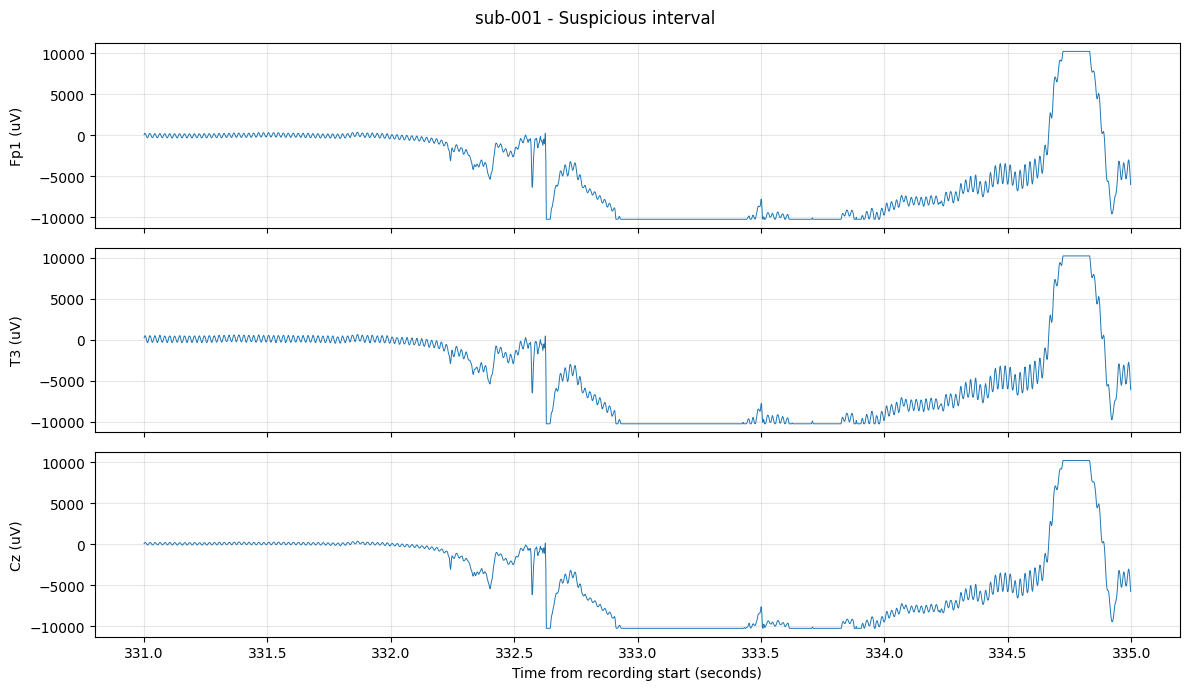

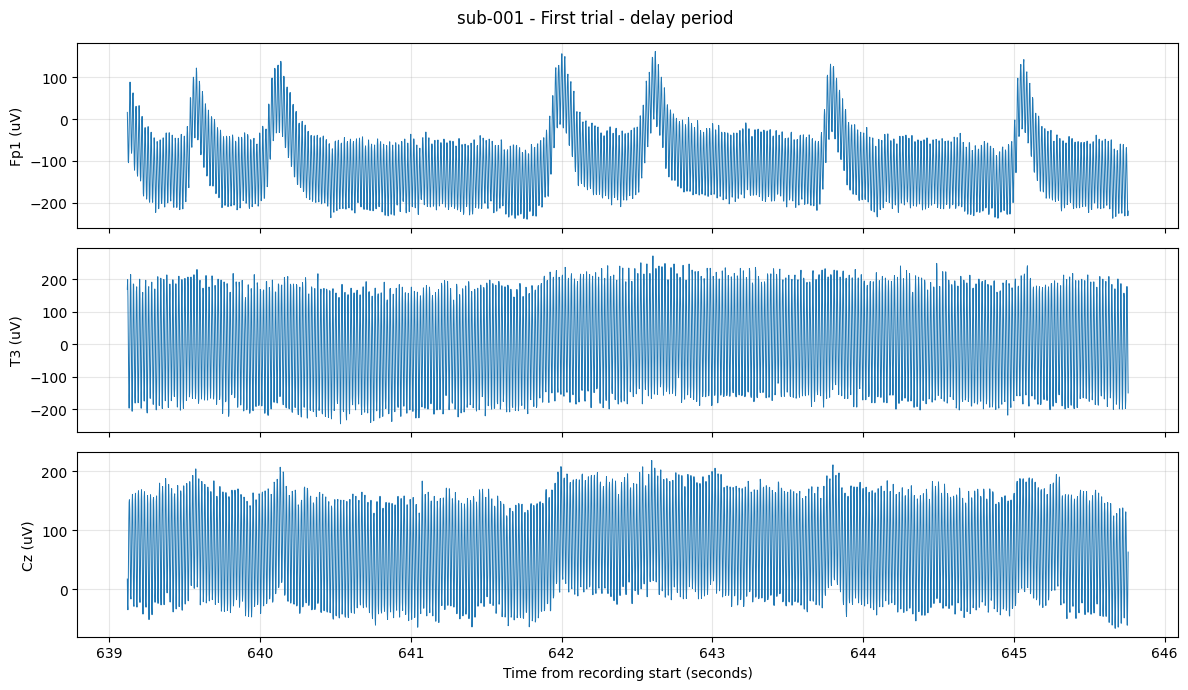

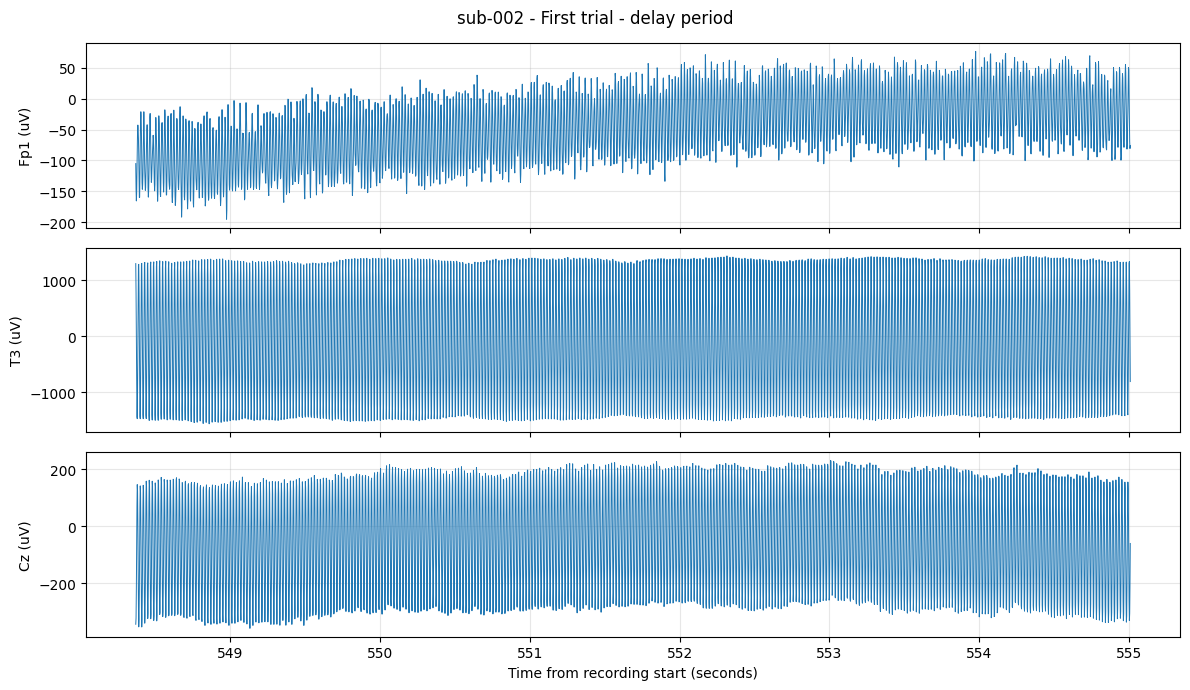

In [ ]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports" / "trial_table.csv")

channels = ["Fp1", "T3", "Cz"]

for participant in ["sub-001", "sub-002"]:
    folder = project / "data" / participant / "eeg"
    eeg_file = next(folder.glob("*_eeg.set"))

    raw = mne.io.read_raw_eeglab(
        eeg_file,
        preload=False,
        verbose="ERROR"
    )

    participant_trials = trials[
        trials["participant_id"] == participant
    ].sort_values("trial_number")

    first_trial = participant_trials.iloc[0]

    windows = [
        (
            "First trial - delay period",
            float(first_trial["delay_onset"]),
            float(first_trial["probe_onset"])
        )
    ]

    if participant == "sub-001":
        windows.insert(
            0,
            ("Suspicious interval", 331.0, 335.0)
        )

    sampling_rate = float(raw.info["sfreq"])

    for label, start_time, end_time in windows:
        start_sample = int(round(start_time * sampling_rate))
        stop_sample = int(round(end_time * sampling_rate))

        values = raw.get_data(
            picks=channels,
            start=start_sample,
            stop=stop_sample
        ) * 1e6

        times = (
            np.arange(values.shape[1]) + start_sample
        ) / sampling_rate

        fig, axes = plt.subplots(
            nrows=3,
            ncols=1,
            figsize=(12, 7),
            sharex=True
        )

        for index, channel in enumerate(channels):
            axes[index].plot(
                times,
                values[index],
                linewidth=0.7
            )
            axes[index].set_ylabel(channel + " (uV)")
            axes[index].grid(alpha=0.3)

        axes[-1].set_xlabel("Time from recording start (seconds)")
        title = participant + " - " + label
        fig.suptitle(title)
        fig.tight_layout()
        plt.show()
        plt.close(fig)

    raw.close()

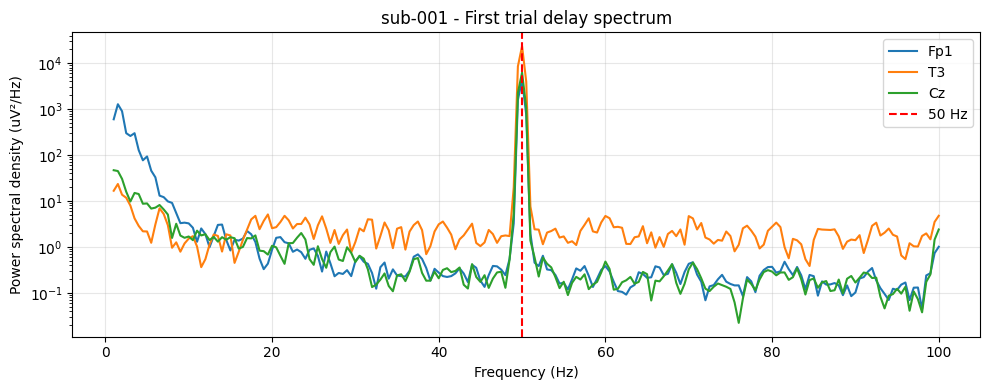

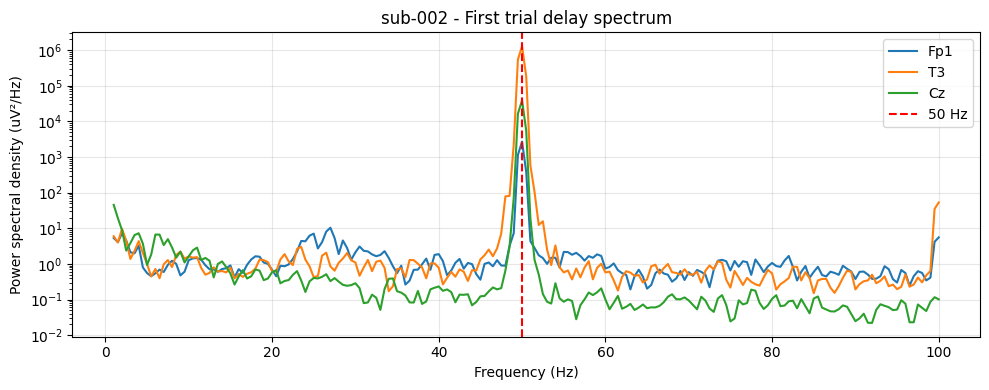

,participant,channel,strongest_frequency_1_to_100_Hz
0,sub-001,Fp1,50.0
1,sub-001,T3,50.0
2,sub-001,Cz,50.0
3,sub-002,Fp1,50.0
4,sub-002,T3,50.0
5,sub-002,Cz,50.0


In [ ]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from pathlib import Path
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")
channels = ["Fp1", "T3", "Cz"]
results = []

for participant in ["sub-001", "sub-002"]:
    eeg_file = next(
        (project / "data" / participant / "eeg").glob("*_eeg.set")
    )
    raw = mne.io.read_raw_eeglab(
        eeg_file, preload=False, verbose="ERROR"
    )

    trial = trials[
        trials["participant_id"] == participant
    ].sort_values("trial_number").iloc[0]

    fs = float(raw.info["sfreq"])
    start = int(round(float(trial["delay_onset"]) * fs))
    stop = int(round(float(trial["probe_onset"]) * fs))

    signals = raw.get_data(
        picks=channels, start=start, stop=stop
    ) * 1e6

    frequencies, power = welch(
        signals,
        fs=fs,
        nperseg=min(signals.shape[1], int(2 * fs)),
        axis=-1
    )

    selected = (frequencies >= 1) & (frequencies <= 100)

    fig, ax = plt.subplots(figsize=(10, 4))

    for index, channel in enumerate(channels):
        ax.semilogy(
            frequencies[selected],
            power[index, selected],
            label=channel
        )

        peak = frequencies[selected][
            np.argmax(power[index, selected])
        ]

        results.append({
            "participant": participant,
            "channel": channel,
            "strongest_frequency_1_to_100_Hz": peak
        })

    ax.axvline(50, color="red", linestyle="--", label="50 Hz")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power spectral density (uV²/Hz)")
    ax.set_title(participant + " - First trial delay spectrum")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    raw.close()

display(pd.DataFrame(results))

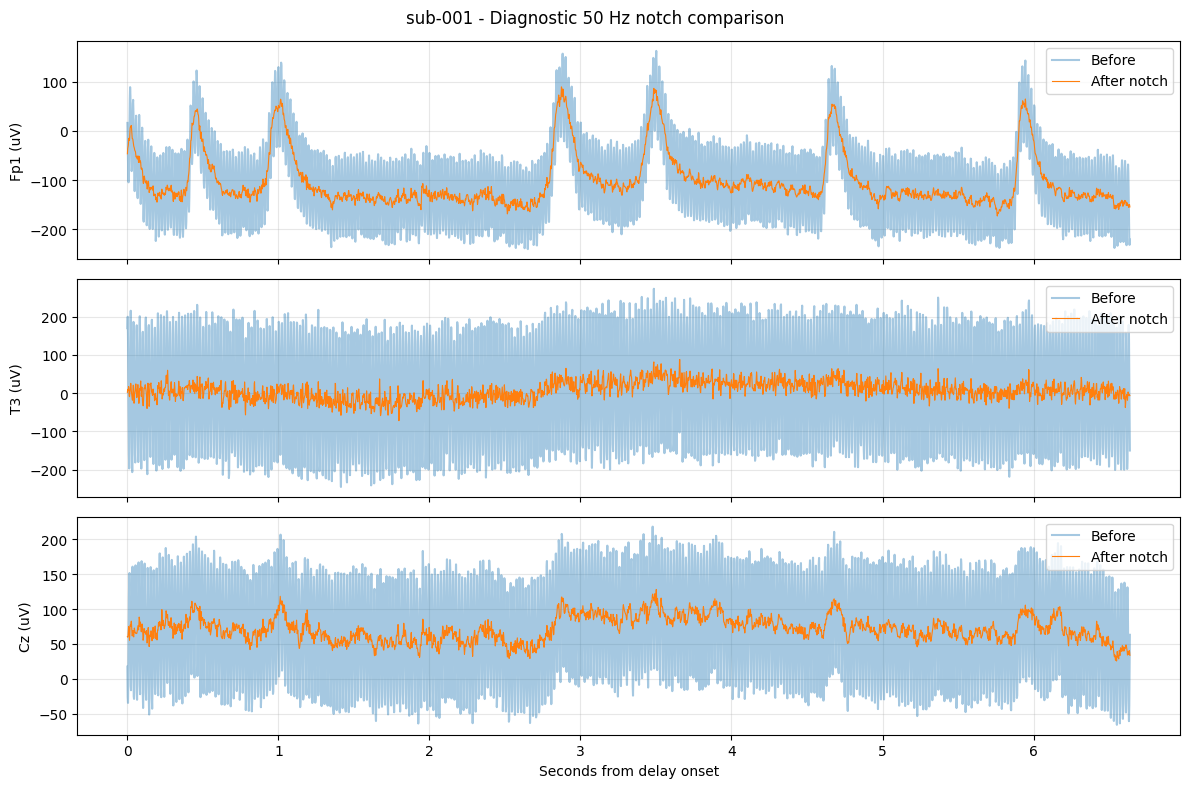

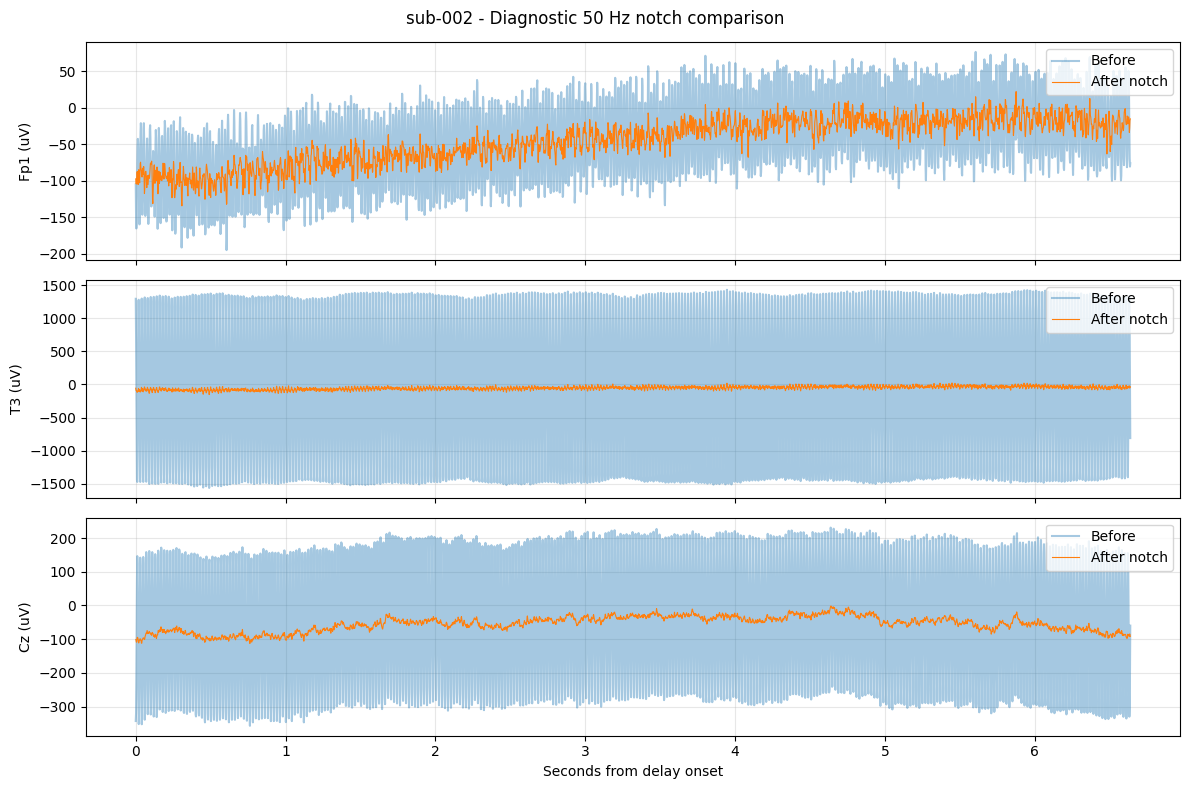

,participant,channel,peak_to_peak_before_uV,peak_to_peak_after_uV,50Hz_PSD_before,50Hz_PSD_after
0,sub-001,Fp1,402.062,261.945,4420.815,0.140
1,sub-001,T3,518.187,159.887,23498.850,0.882
2,sub-001,Cz,284.438,102.724,6256.956,0.221
3,sub-002,Fp1,271.312,156.404,2720.622,0.393
4,sub-002,T3,2989.500,175.310,1298842.373,182.909
5,sub-002,Cz,588.500,111.065,38976.303,5.450


In [ ]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, filtfilt, welch
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")
channels = ["Fp1", "T3", "Cz"]
comparison = []

for participant in ["sub-001", "sub-002"]:
    eeg_file = next(
        (project / "data" / participant / "eeg").glob("*_eeg.set")
    )
    raw = mne.io.read_raw_eeglab(
        eeg_file, preload=False, verbose="ERROR"
    )

    trial = trials[
        trials["participant_id"] == participant
    ].sort_values("trial_number").iloc[0]

    fs = float(raw.info["sfreq"])
    start = int(round(float(trial["delay_onset"]) * fs))
    stop = int(round(float(trial["probe_onset"]) * fs))
    padding = int(10 * fs)

    padded_start = max(0, start - padding)
    padded_stop = min(raw.n_times, stop + padding)

    signal = raw.get_data(
        picks=channels, start=padded_start, stop=padded_stop
    ) * 1e6

    # Diagnostic notch centered at 50 Hz, with quality factor 30.
    b, a = iirnotch(50.0, Q=30.0, fs=fs)
    filtered = filtfilt(b, a, signal, axis=-1)

    left = start - padded_start
    right = stop - padded_start
    before = signal[:, left:right]
    after = filtered[:, left:right]
    times = np.arange(before.shape[1]) / fs

    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

    for index, channel in enumerate(channels):
        axes[index].plot(
            times, before[index], alpha=0.4, label="Before"
        )
        axes[index].plot(
            times, after[index], linewidth=0.8, label="After notch"
        )
        axes[index].set_ylabel(channel + " (uV)")
        axes[index].legend(loc="upper right")
        axes[index].grid(alpha=0.3)

        frequencies, psd_before = welch(
            before[index], fs=fs, nperseg=int(2 * fs)
        )
        _, psd_after = welch(
            after[index], fs=fs, nperseg=int(2 * fs)
        )
        bin_50 = np.argmin(np.abs(frequencies - 50))

        comparison.append({
            "participant": participant,
            "channel": channel,
            "peak_to_peak_before_uV": np.ptp(before[index]),
            "peak_to_peak_after_uV": np.ptp(after[index]),
            "50Hz_PSD_before": psd_before[bin_50],
            "50Hz_PSD_after": psd_after[bin_50]
        })

    axes[-1].set_xlabel("Seconds from delay onset")
    fig.suptitle(participant + " - Diagnostic 50 Hz notch comparison")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    raw.close()

display(pd.DataFrame(comparison).round(3))

In [ ]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import shutil
import pandas as pd

drive.mount("/content/drive")

project = Path("/content/federated-eeg-working-memory")
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")

checkpoint = (
    Path("/content/drive/MyDrive")
    / "EEG_Project"
    / "checkpoints"
    / stamp
)
checkpoint.mkdir(parents=True, exist_ok=True)

# Save the diagnostic results from the previous cell.
pd.DataFrame(comparison).to_csv(
    project / "reports" / "notch_first_trial_comparison.csv",
    index=False
)

# Preserve current report files.
shutil.copytree(
    project / "reports",
    checkpoint / "reports"
)

print("Checkpoint saved:")
print(checkpoint)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint saved:
/content/drive/MyDrive/EEG_Project/checkpoints/20261107_105720_UTC


In [ ]:
from pathlib import Path
from datetime import datetime, timezone

import mne
import numpy as np
import pandas as pd
from scipy.signal import iirnotch, filtfilt
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")
rows = []

# Screening threshold near the observed amplitude boundary.
boundary_threshold_uv = 10239.0

for participant, participant_trials in trials.groupby("participant_id"):
    print("Checking", participant, flush=True)

    eeg_file = next(
        (project / "data" / participant / "eeg").glob("*_eeg.set")
    )
    raw = mne.io.read_raw_eeglab(
        eeg_file, preload=False, verbose="ERROR"
    )
    raw.set_channel_types({"EOGv": "eog", "EOGh": "eog"})

    picks = mne.pick_types(raw.info, eeg=True, eog=False, exclude=[])
    channel_names = [raw.ch_names[index] for index in picks]

    fs = float(raw.info["sfreq"])
    padding = int(10 * fs)
    b, a = iirnotch(50.0, Q=30.0, fs=fs)

    for trial in participant_trials.itertuples(index=False):
        start = int(round(trial.delay_onset * fs))
        stop = int(round(trial.probe_onset * fs))

        if not 0 <= start < stop <= raw.n_times:
            raise ValueError(
                f"Invalid window: {participant}, trial {trial.trial_number}"
            )

        padded_start = max(0, start - padding)
        padded_stop = min(raw.n_times, stop + padding)

        signal = raw.get_data(
            picks=picks, start=padded_start, stop=padded_stop
        ) * 1e6

        if not np.isfinite(signal).all():
            raise ValueError(
                f"Non-finite signal: {participant}, trial {trial.trial_number}"
            )

        filtered = filtfilt(b, a, signal, axis=-1)

        left = start - padded_start
        right = stop - padded_start
        before = signal[:, left:right]
        after = filtered[:, left:right]

        ptp_before = np.ptp(before, axis=1)
        ptp_after = np.ptp(after, axis=1)

        rows.append({
            "participant_id": participant,
            "trial_number": trial.trial_number,
            "condition": trial.condition,
            "max_ptp_before_uV": float(ptp_before.max()),
            "max_ptp_after_uV": float(ptp_after.max()),
            "largest_channel_after": channel_names[int(ptp_after.argmax())],
            "channels_over_500uV_after": int((ptp_after > 500).sum()),
            "boundary_in_delay": bool(
                (np.abs(before) >= boundary_threshold_uv).any()
            ),
            "boundary_in_padded_segment": bool(
                (np.abs(signal) >= boundary_threshold_uv).any()
            )
        })

    raw.close()
    print("Completed", participant, flush=True)

audit = pd.DataFrame(rows)

report_path = project / "reports" / "all_trials_notch_audit.csv"
audit.to_csv(report_path, index=False)

drive_folder = Path("/content/drive/MyDrive/EEG_Project/checkpoints")
if not drive_folder.is_dir():
    raise RuntimeError("Mount Drive before saving this audit.")

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
drive_path = drive_folder / f"all_trials_notch_audit_{stamp}.csv"
audit.to_csv(drive_path, index=False)

summary = audit.groupby("participant_id").agg(
    trials=("trial_number", "size"),
    median_max_ptp_before_uV=("max_ptp_before_uV", "median"),
    median_max_ptp_after_uV=("max_ptp_after_uV", "median"),
    highest_ptp_after_uV=("max_ptp_after_uV", "max"),
    delay_boundary_flags=("boundary_in_delay", "sum"),
    padded_segment_boundary_flags=("boundary_in_padded_segment", "sum")
)

display(summary.round(3))

print("Ten trials with highest amplitude after notch:")
display(
    audit.nlargest(10, "max_ptp_after_uV")
    .reset_index(drop=True)
    .round(3)
)

print("Saved to Drive:", drive_path)

Checking sub-001
Completed sub-001
Checking sub-002
Completed sub-002


,trials,median_max_ptp_before_uV,median_max_ptp_after_uV,highest_ptp_after_uV,delay_boundary_flags,padded_segment_boundary_flags
participant_id,,,,,,
sub-001,120,410.812,241.577,1545.872,0,0
sub-002,120,2551.438,182.802,834.683,0,0


Ten trials with highest amplitude after notch:


,participant_id,trial_number,condition,max_ptp_before_uV,max_ptp_after_uV,largest_channel_after,channels_over_500uV_after,boundary_in_delay,boundary_in_padded_segment
0,sub-001,116,7M,1612.188,1545.872,Fp2,19,False,False
1,sub-002,81,5M,2489.812,834.683,Pz,1,False,False
2,sub-002,94,5M,2457.438,581.262,Pz,1,False,False
3,sub-002,15,6M,2824.250,579.091,Fp1,1,False,False
4,sub-002,82,5M,2492.250,572.571,Pz,1,False,False
5,sub-001,96,5R,699.875,566.956,Fp2,2,False,False
6,sub-002,74,6R,2480.000,533.466,Pz,1,False,False
7,sub-002,11,6M,2860.625,531.386,Fp2,1,False,False
8,sub-002,89,5M,2480.562,456.828,Pz,0,False,False
9,sub-002,85,5M,2471.188,452.346,Pz,0,False,False


Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/all_trials_notch_audit_20261107_110033_UTC.csv


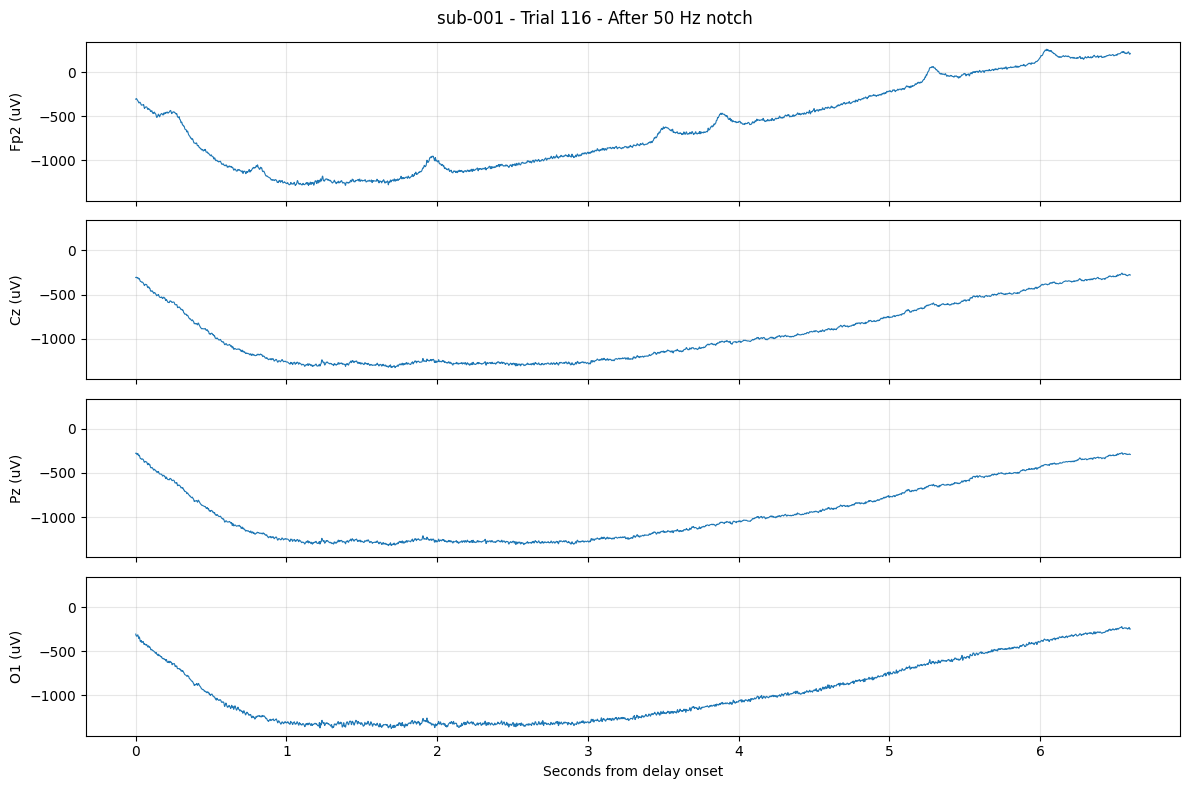

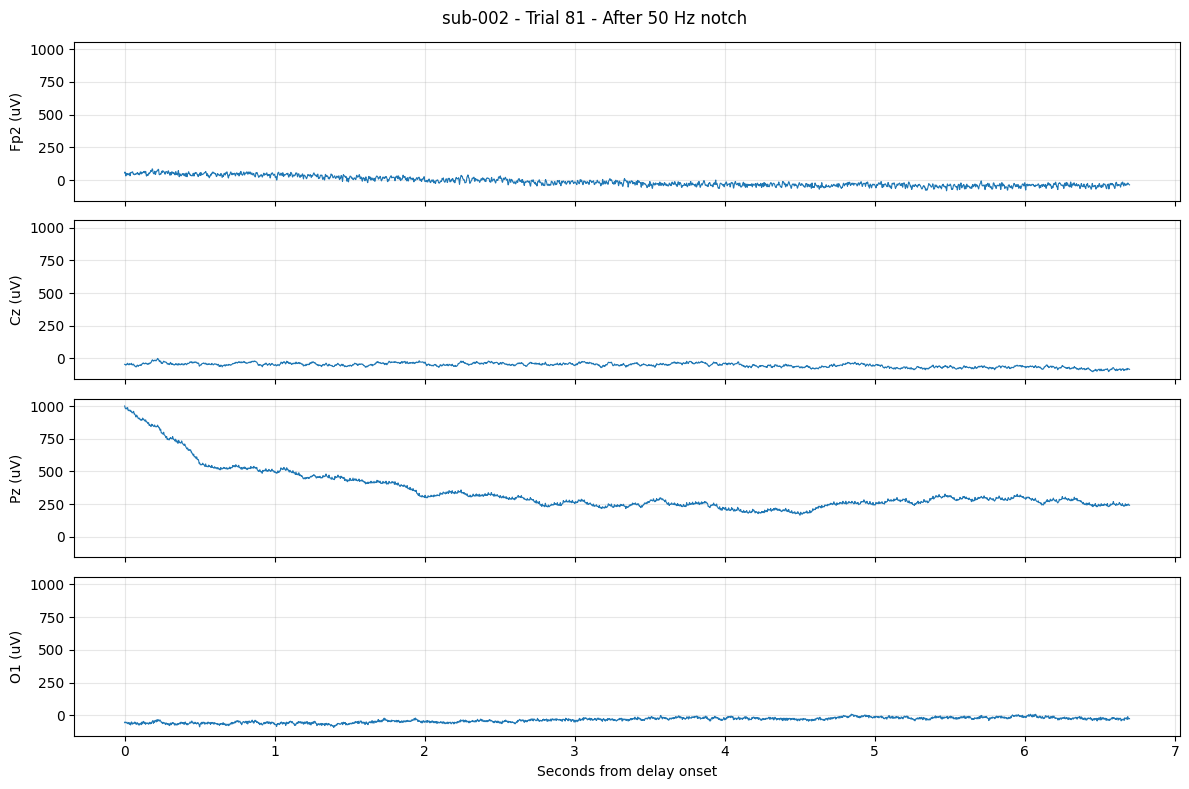

In [ ]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, filtfilt

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")

cases = [("sub-001", 116), ("sub-002", 81)]
channels = ["Fp2", "Cz", "Pz", "O1"]

for participant, trial_number in cases:
    trial = trials[
        (trials["participant_id"] == participant)
        & (trials["trial_number"] == trial_number)
    ].iloc[0]

    eeg_file = next(
        (project / "data" / participant / "eeg").glob("*_eeg.set")
    )
    raw = mne.io.read_raw_eeglab(
        eeg_file, preload=False, verbose="ERROR"
    )

    fs = float(raw.info["sfreq"])
    start = int(round(trial["delay_onset"] * fs))
    stop = int(round(trial["probe_onset"] * fs))
    padded_start = max(0, start - int(10 * fs))
    padded_stop = min(raw.n_times, stop + int(10 * fs))

    signal = raw.get_data(
        picks=channels,
        start=padded_start,
        stop=padded_stop
    ) * 1e6

    b, a = iirnotch(50.0, Q=30.0, fs=fs)
    filtered = filtfilt(b, a, signal, axis=-1)

    left = start - padded_start
    right = stop - padded_start
    window = filtered[:, left:right]
    times = np.arange(window.shape[1]) / fs

    fig, axes = plt.subplots(
        4, 1, figsize=(12, 8), sharex=True, sharey=True
    )

    for index, channel in enumerate(channels):
        axes[index].plot(times, window[index], linewidth=0.8)
        axes[index].set_ylabel(channel + " (uV)")
        axes[index].grid(alpha=0.3)

    axes[-1].set_xlabel("Seconds from delay onset")
    title = participant + " - Trial " + str(trial_number)
    fig.suptitle(title + " - After 50 Hz notch")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    raw.close()

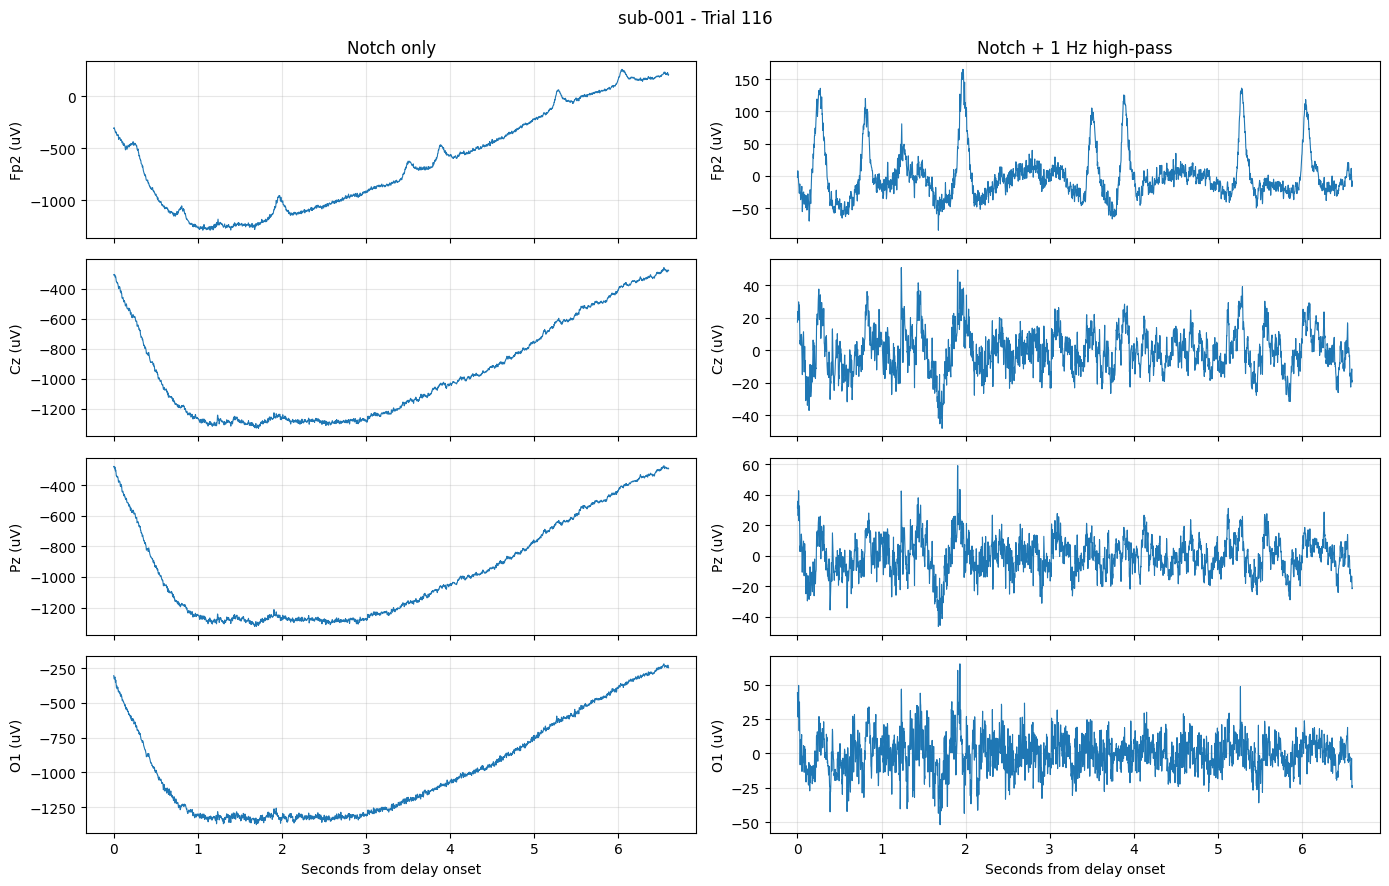

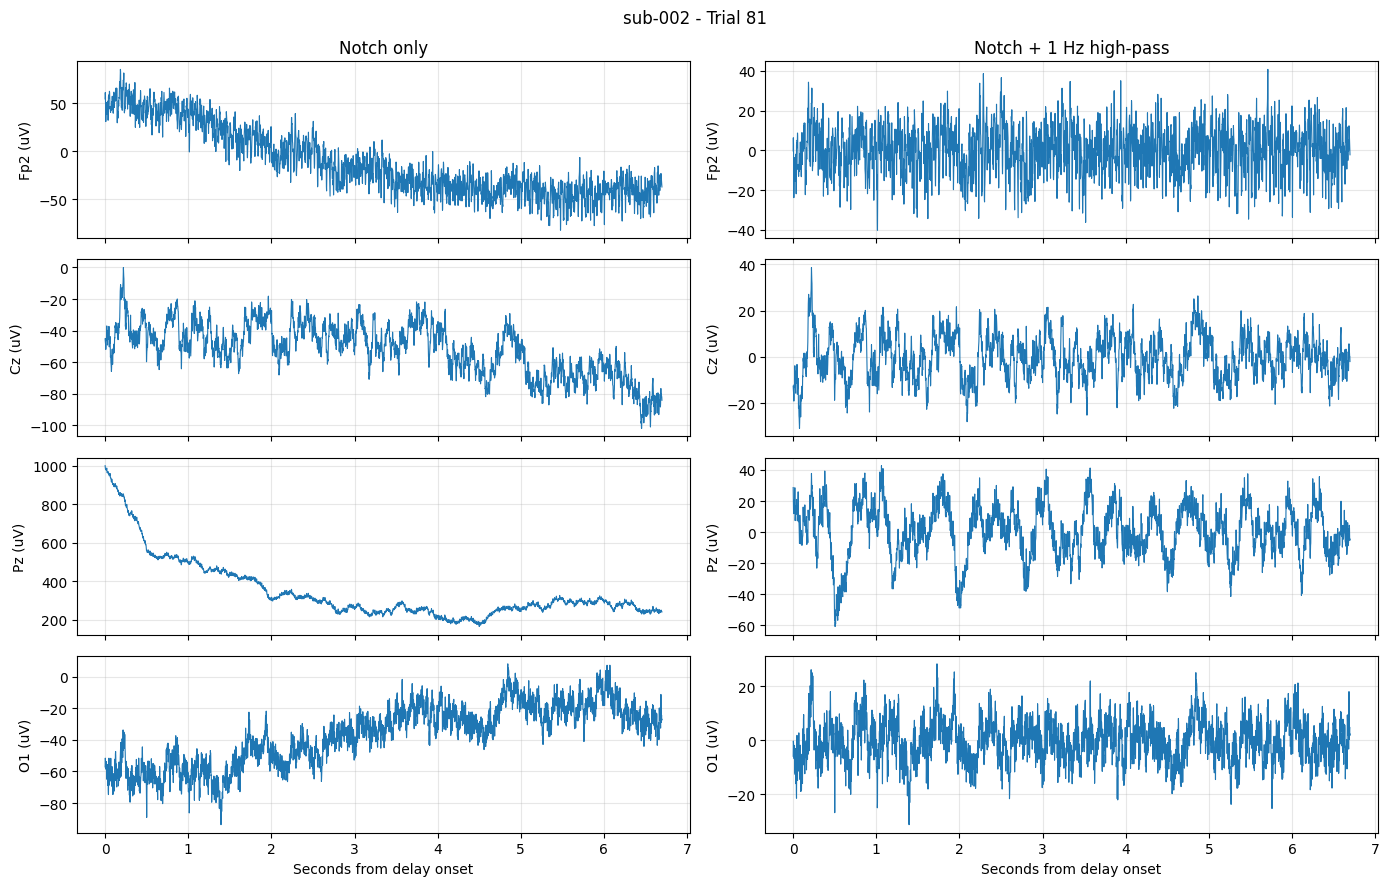

,participant,trial,channel,notch_only_ptp_uV,notch_plus_highpass_ptp_uV
0,sub-001,116,Fp2,1545.872,248.902
1,sub-001,116,Cz,1072.506,98.955
2,sub-001,116,Pz,1054.023,105.657
3,sub-001,116,O1,1156.151,116.928
4,sub-002,81,Fp2,168.129,80.932
5,sub-002,81,Cz,101.814,69.442
6,sub-002,81,Pz,834.683,103.438
7,sub-002,81,O1,101.832,59.696


In [ ]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, filtfilt, butter, sosfiltfilt
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")
channels = ["Fp2", "Cz", "Pz", "O1"]
results = []

for participant, trial_number in [("sub-001", 116), ("sub-002", 81)]:
    trial = trials[
        (trials["participant_id"] == participant)
        & (trials["trial_number"] == trial_number)
    ].iloc[0]

    eeg_file = next(
        (project / "data" / participant / "eeg").glob("*_eeg.set")
    )
    raw = mne.io.read_raw_eeglab(
        eeg_file, preload=False, verbose="ERROR"
    )

    fs = float(raw.info["sfreq"])
    start = int(round(trial["delay_onset"] * fs))
    stop = int(round(trial["probe_onset"] * fs))
    padded_start = max(0, start - int(10 * fs))
    padded_stop = min(raw.n_times, stop + int(10 * fs))

    signal = raw.get_data(
        picks=channels, start=padded_start, stop=padded_stop
    ) * 1e6

    b, a = iirnotch(50.0, Q=30.0, fs=fs)
    notch = filtfilt(b, a, signal, axis=-1)

    sos = butter(4, 1.0, btype="highpass", fs=fs, output="sos")
    highpass = sosfiltfilt(sos, notch, axis=-1)

    left = start - padded_start
    right = stop - padded_start
    before = notch[:, left:right]
    after = highpass[:, left:right]
    times = np.arange(after.shape[1]) / fs

    fig, axes = plt.subplots(4, 2, figsize=(14, 9), sharex=True)

    for index, channel in enumerate(channels):
        axes[index, 0].plot(times, before[index], linewidth=0.8)
        axes[index, 1].plot(times, after[index], linewidth=0.8)

        for column in [0, 1]:
            axes[index, column].set_ylabel(channel + " (uV)")
            axes[index, column].grid(alpha=0.3)

        results.append({
            "participant": participant,
            "trial": trial_number,
            "channel": channel,
            "notch_only_ptp_uV": np.ptp(before[index]),
            "notch_plus_highpass_ptp_uV": np.ptp(after[index])
        })

    axes[0, 0].set_title("Notch only")
    axes[0, 1].set_title("Notch + 1 Hz high-pass")

    for column in [0, 1]:
        axes[-1, column].set_xlabel("Seconds from delay onset")

    fig.suptitle(participant + " - Trial " + str(trial_number))
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    raw.close()

display(pd.DataFrame(results).round(3))

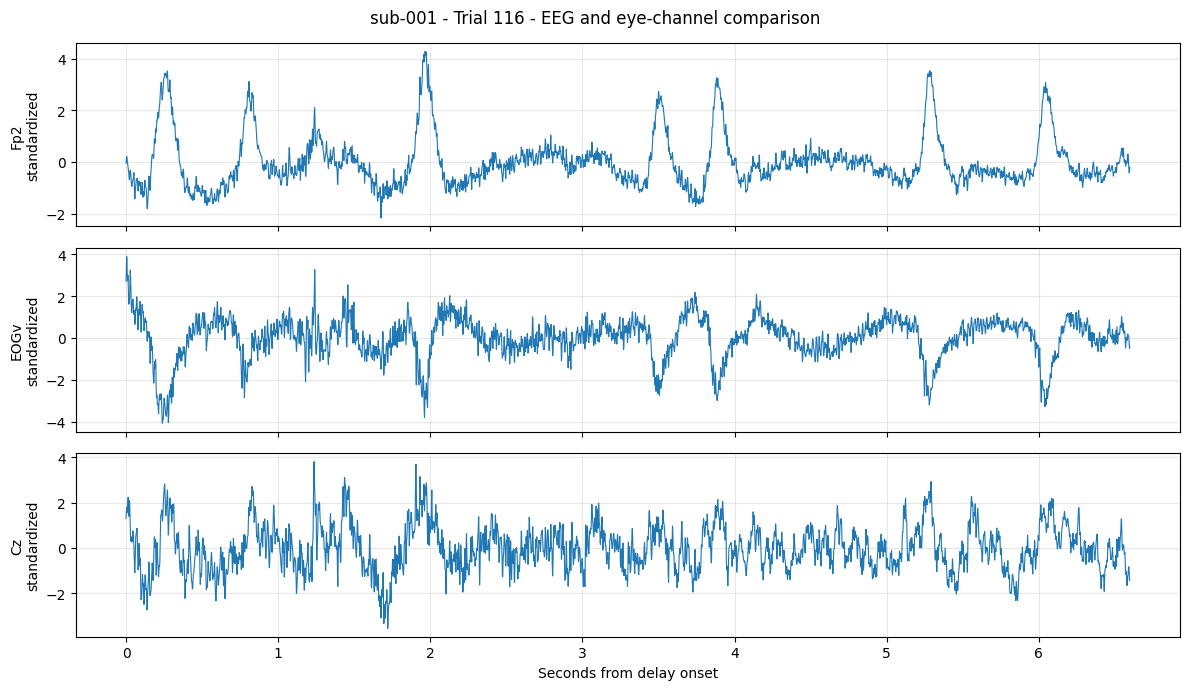

In [ ]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, filtfilt, butter, sosfiltfilt

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")

trial = trials[
    (trials["participant_id"] == "sub-001")
    & (trials["trial_number"] == 116)
].iloc[0]

eeg_file = next(
    (project / "data/sub-001/eeg").glob("*_eeg.set")
)
raw = mne.io.read_raw_eeglab(
    eeg_file, preload=False, verbose="ERROR"
)
raw.set_channel_types({"EOGv": "eog", "EOGh": "eog"})

channels = ["Fp2", "EOGv", "Cz"]
fs = float(raw.info["sfreq"])

start = int(round(trial["delay_onset"] * fs))
stop = int(round(trial["probe_onset"] * fs))
padded_start = max(0, start - int(10 * fs))
padded_stop = min(raw.n_times, stop + int(10 * fs))

signal = raw.get_data(
    picks=channels, start=padded_start, stop=padded_stop
)

b, a = iirnotch(50.0, Q=30.0, fs=fs)
filtered = filtfilt(b, a, signal, axis=-1)

sos = butter(4, 1.0, btype="highpass", fs=fs, output="sos")
filtered = sosfiltfilt(sos, filtered, axis=-1)

window = filtered[:, start - padded_start:stop - padded_start]

# Standardize each trace to compare timing and shape.
# EOG units were missing in the channel metadata.
centered = window - window.mean(axis=1, keepdims=True)
spread = window.std(axis=1, keepdims=True)
normalized = centered / np.where(spread > 0, spread, 1.0)

times = np.arange(window.shape[1]) / fs
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

for index, channel in enumerate(channels):
    axes[index].plot(times, normalized[index], linewidth=0.8)
    axes[index].set_ylabel(channel + "\nstandardized")
    axes[index].grid(alpha=0.3)

axes[-1].set_xlabel("Seconds from delay onset")
fig.suptitle("sub-001 - Trial 116 - EEG and eye-channel comparison")
fig.tight_layout()
plt.show()
plt.close(fig)
raw.close()

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import mne
import numpy as np
import pandas as pd
from scipy.signal import iirnotch, filtfilt, butter, sosfiltfilt
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")
records = []

for participant, participant_trials in trials.groupby("participant_id"):
    print("Checking", participant, flush=True)

    eeg_file = next(
        (project / "data" / participant / "eeg").glob("*_eeg.set")
    )
    raw = mne.io.read_raw_eeglab(
        eeg_file, preload=False, verbose="ERROR"
    )
    raw.set_channel_types({"EOGv": "eog", "EOGh": "eog"})

    eeg_picks = mne.pick_types(
        raw.info, eeg=True, eog=False, exclude=[]
    )
    eeg_names = [raw.ch_names[i] for i in eeg_picks]
    names = eeg_names + ["EOGv"]

    fs = float(raw.info["sfreq"])
    b, a = iirnotch(50.0, Q=30.0, fs=fs)
    sos = butter(4, 1.0, btype="highpass", fs=fs, output="sos")

    for trial in participant_trials.itertuples(index=False):
        start = int(round(trial.delay_onset * fs))
        stop = int(round(trial.probe_onset * fs))

        if not 0 <= start < stop <= raw.n_times:
            raise ValueError("Invalid window for trial " + str(trial.trial_number))

        padded_start = max(0, start - int(10 * fs))
        padded_stop = min(raw.n_times, stop + int(10 * fs))

        signal = raw.get_data(
            picks=names, start=padded_start, stop=padded_stop
        )

        if not np.isfinite(signal).all():
            raise ValueError("Non-finite samples found")

        filtered = filtfilt(b, a, signal, axis=-1)
        filtered = sosfiltfilt(sos, filtered, axis=-1)

        left = start - padded_start
        right = stop - padded_start
        window = filtered[:, left:right]
        eeg_uv = window[:-1] * 1e6
        eog = window[-1]

        ptp = np.ptp(eeg_uv, axis=1)

        record = {
            "participant_id": participant,
            "trial_number": trial.trial_number,
            "condition": trial.condition,
            "max_ptp_after_uV": float(ptp.max()),
            "largest_channel": eeg_names[int(ptp.argmax())],
            "boundary_in_padded_segment": bool(
                (np.abs(signal[:-1] * 1e6) >= 10239.0).any()
            )
        }

        for frontal in ["Fp1", "Fp2"]:
            trace = window[names.index(frontal)]
            correlation = np.nan
            if trace.std() > 0 and eog.std() > 0:
                correlation = float(np.corrcoef(trace, eog)[0, 1])
            record[frontal + "_EOGv_r"] = correlation

        records.append(record)

    raw.close()

quality = pd.DataFrame(records)
quality["max_abs_frontal_EOG_r"] = quality[
    ["Fp1_EOGv_r", "Fp2_EOGv_r"]
].abs().max(axis=1)

local_path = project / "reports" / "filtered_trial_quality.csv"
quality.to_csv(local_path, index=False)

drive_folder = Path("/content/drive/MyDrive/EEG_Project/checkpoints")
if not drive_folder.is_dir():
    raise RuntimeError("Mount Drive to save the checkpoint.")

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
quality.to_csv(
    drive_folder / f"filtered_trial_quality_{stamp}.csv",
    index=False
)

print("Highest remaining amplitudes:")
display(quality.nlargest(10, "max_ptp_after_uV").round(3))

print("Strongest frontal EEG / EOG associations:")
display(quality.nlargest(10, "max_abs_frontal_EOG_r").round(3))

print("Trial rows saved:", len(quality))
print("Saved locally and to Drive.")

Checking sub-001
Checking sub-002
Highest remaining amplitudes:


,participant_id,trial_number,condition,max_ptp_after_uV,largest_channel,boundary_in_padded_segment,Fp1_EOGv_r,Fp2_EOGv_r,max_abs_frontal_EOG_r
134,sub-002,15,6M,563.322,Fp1,False,-0.552,-0.513,0.552
130,sub-002,11,6M,452.175,Fp2,False,-0.782,-0.792,0.792
136,sub-002,17,6M,375.841,Fp2,False,-0.693,-0.712,0.712
140,sub-002,21,7M,360.105,Fp1,False,-0.669,-0.674,0.674
114,sub-001,115,7M,349.923,Fp1,False,-0.914,-0.918,0.918
146,sub-002,27,7M,342.543,Fp1,False,-0.599,-0.596,0.599
207,sub-002,88,5M,329.879,Fp2,False,-0.536,-0.608,0.608
116,sub-001,117,7M,323.207,Fp2,False,-0.678,-0.685,0.685
169,sub-002,50,7R,320.208,Fp1,False,-0.633,-0.672,0.672
150,sub-002,31,7M,317.259,Fp1,False,-0.649,-0.660,0.660


Strongest frontal EEG / EOG associations:


,participant_id,trial_number,condition,max_ptp_after_uV,largest_channel,boundary_in_padded_segment,Fp1_EOGv_r,Fp2_EOGv_r,max_abs_frontal_EOG_r
1,sub-001,2,6M,232.639,Fp2,False,-0.935,-0.943,0.943
60,sub-001,61,5M,232.747,Fp2,False,-0.931,-0.938,0.938
11,sub-001,12,6M,227.616,Fp2,False,-0.929,-0.937,0.937
68,sub-001,69,5M,232.247,Fp2,False,-0.929,-0.935,0.935
70,sub-001,71,5M,237.727,Fp2,False,-0.929,-0.933,0.933
65,sub-001,66,5M,187.539,Fp2,False,-0.929,-0.932,0.932
19,sub-001,20,6M,222.623,Fp2,False,-0.922,-0.929,0.929
6,sub-001,7,6M,234.136,Fp2,False,-0.927,-0.920,0.927
66,sub-001,67,5M,240.545,Fp2,False,-0.921,-0.924,0.924
63,sub-001,64,5M,227.184,Fp2,False,-0.913,-0.920,0.920


Trial rows saved: 240
Saved locally and to Drive.


In [ ]:
import pandas as pd
from IPython.display import display

quality = pd.read_csv(
    "/content/federated-eeg-working-memory/"
    "reports/filtered_trial_quality.csv"
)

summary = quality.groupby("participant_id").agg(
    total_trials=("trial_number", "size"),
    median_max_amplitude_uV=("max_ptp_after_uV", "median"),
    highest_amplitude_uV=("max_ptp_after_uV", "max"),
    median_abs_EOG_correlation=("max_abs_frontal_EOG_r", "median"),
    highest_abs_EOG_correlation=("max_abs_frontal_EOG_r", "max"),
    boundary_flagged_trials=("boundary_in_padded_segment", "sum")
)

display(summary.round(3))

,total_trials,median_max_amplitude_uV,highest_amplitude_uV,median_abs_EOG_correlation,highest_abs_EOG_correlation,boundary_flagged_trials
participant_id,,,,,,
sub-001,120,195.470,349.923,0.847,0.943,0
sub-002,120,105.562,563.322,0.321,0.792,0


In [ ]:
from pathlib import Path
import warnings
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
trials = pd.read_csv(project / "reports/trial_table.csv")
subject_trials = trials[trials["participant_id"] == "sub-001"]

eeg_file = next(
    (project / "data/sub-001/eeg").glob("*_eeg.set")
)

raw_ica = mne.io.read_raw_eeglab(
    eeg_file, preload=False, verbose="ERROR"
)
raw_ica.set_channel_types({"EOGv": "eog", "EOGh": "eog"})

# Use the task interval with context on both sides.
start_time = max(0, float(subject_trials["delay_onset"].min()) - 10)
end_time = min(
    raw_ica.times[-1],
    float(subject_trials["probe_onset"].max()) + 10
)

raw_ica.crop(tmin=start_time, tmax=end_time).load_data()

eeg = raw_ica.get_data(picks="eeg")
if not np.isfinite(eeg).all():
    raise ValueError("Non-finite EEG values found. Inspect before ICA.")

if (np.abs(eeg) * 1e6 >= 10239.0).any():
    raise ValueError(
        "Boundary-level samples found in the continuous task interval. "
        "Inspect and annotate these before ICA."
    )
del eeg

# Apply the same diagnostic filters to EEG and EOG.
picks = mne.pick_types(raw_ica.info, eeg=True, eog=True, exclude=[])

raw_ica.notch_filter(
    freqs=[50],
    picks=picks,
    method="iir",
    verbose="ERROR"
)
raw_ica.filter(
    l_freq=1,
    h_freq=40,
    picks=picks,
    method="iir",
    iir_params={"order": 4, "ftype": "butter"},
    verbose="ERROR"
)
raw_ica.resample(100, verbose="ERROR")

ica = mne.preprocessing.ICA(
    n_components=0.99,
    method="fastica",
    random_state=42,
    max_iter=1000
)

with warnings.catch_warnings(record=True) as recorded:
    warnings.simplefilter("always", ConvergenceWarning)
    ica.fit(raw_ica, picks="eeg", verbose="ERROR")

if any(issubclass(w.category, ConvergenceWarning) for w in recorded):
    raise RuntimeError(
        "ICA did not converge. Share this message before proceeding."
    )

scores = ica.score_sources(
    raw_ica,
    target="EOGv",
    score_func="pearsonr",
    verbose="ERROR"
)

component_table = pd.DataFrame({
    "component": np.arange(len(scores)),
    "EOGv_correlation": scores,
    "absolute_correlation": np.abs(scores)
}).sort_values("absolute_correlation", ascending=False)

print("ICA components:", ica.n_components_)
print("Iterations:", ica.n_iter_)
display(component_table.round(3))

print("Components currently excluded:", ica.exclude)

Reading 0 ... 1222990  =      0.000 ...  2445.980 secs...
Use rng= instead of random_state= in new code
ICA components: 12
Iterations: 22


,component,EOGv_correlation,absolute_correlation
0,0,0.856,0.856
4,4,-0.131,0.131
5,5,-0.124,0.124
1,1,-0.071,0.071
2,2,0.061,0.061
9,9,-0.057,0.057
11,11,0.038,0.038
8,8,0.034,0.034
7,7,-0.024,0.024
3,3,0.024,0.024


Components currently excluded: []


/tmp/ipykernel_8288/2935091515.py:6: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")


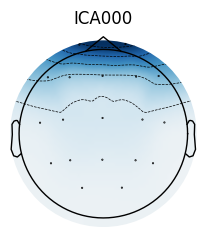

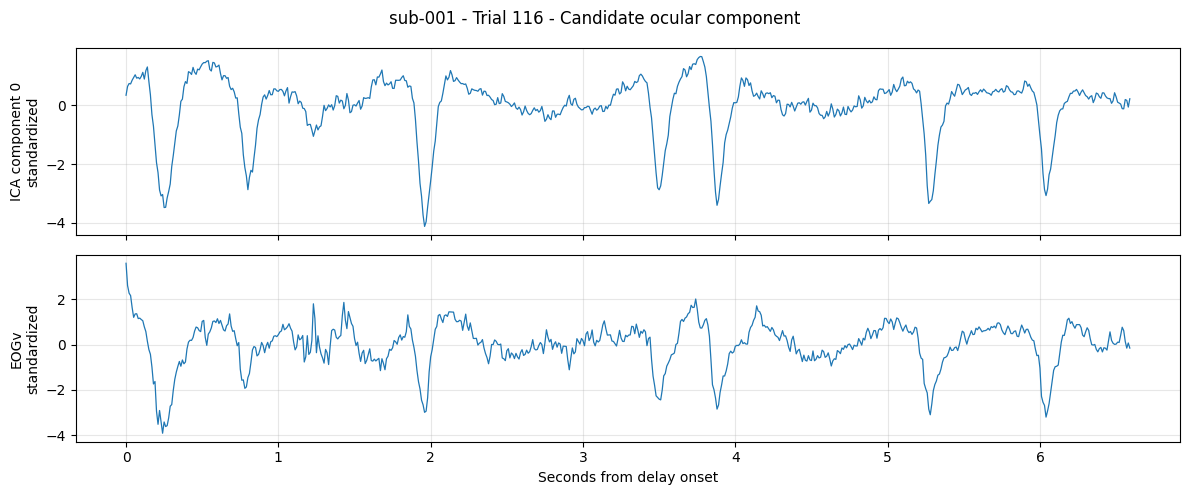

In [ ]:
import mne
import numpy as np
import matplotlib.pyplot as plt

# Add standard electrode positions to a plotting copy.
montage = mne.channels.make_standard_montage("standard_1020")

ica_plot = ica.copy()
ica_plot.info.set_montage(
    montage,
    match_case=False,
    on_missing="raise"
)

# Display component 0's spatial pattern.
ica_plot.plot_components(picks=[0], show=True)

# Find trial 116.
trial = subject_trials[
    subject_trials["trial_number"] == 116
].iloc[0]

fs = float(raw_ica.info["sfreq"])

# Convert original event times to cropped-recording sample indices.
start = int(round(
    (float(trial["delay_onset"]) - raw_ica.first_time) * fs
))
stop = int(round(
    (float(trial["probe_onset"]) - raw_ica.first_time) * fs
))

if not 0 <= start < stop <= raw_ica.n_times:
    raise ValueError("Trial timing is outside the ICA recording.")

# Extract component 0 and vertical eye-channel signals.
sources = ica.get_sources(raw_ica)

component = sources.get_data(
    picks=[0],
    start=start,
    stop=stop
)[0]

eog = raw_ica.get_data(
    picks=["EOGv"],
    start=start,
    stop=stop
)[0]

times = np.arange(len(component)) / fs

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 5),
    sharex=True
)

signals = [component, eog]
labels = ["ICA component 0", "EOGv"]

for axis, values, label in zip(axes, signals, labels):
    centered = values - values.mean()
    spread = values.std()

    if spread > 0:
        standardized = centered / spread
    else:
        standardized = centered

    axis.plot(times, standardized, linewidth=0.9)
    axis.set_ylabel(label + "\nstandardized")
    axis.grid(alpha=0.3)

axes[-1].set_xlabel("Seconds from delay onset")
fig.suptitle("sub-001 - Trial 116 - Candidate ocular component")
fig.tight_layout()
plt.show()
plt.close(fig)

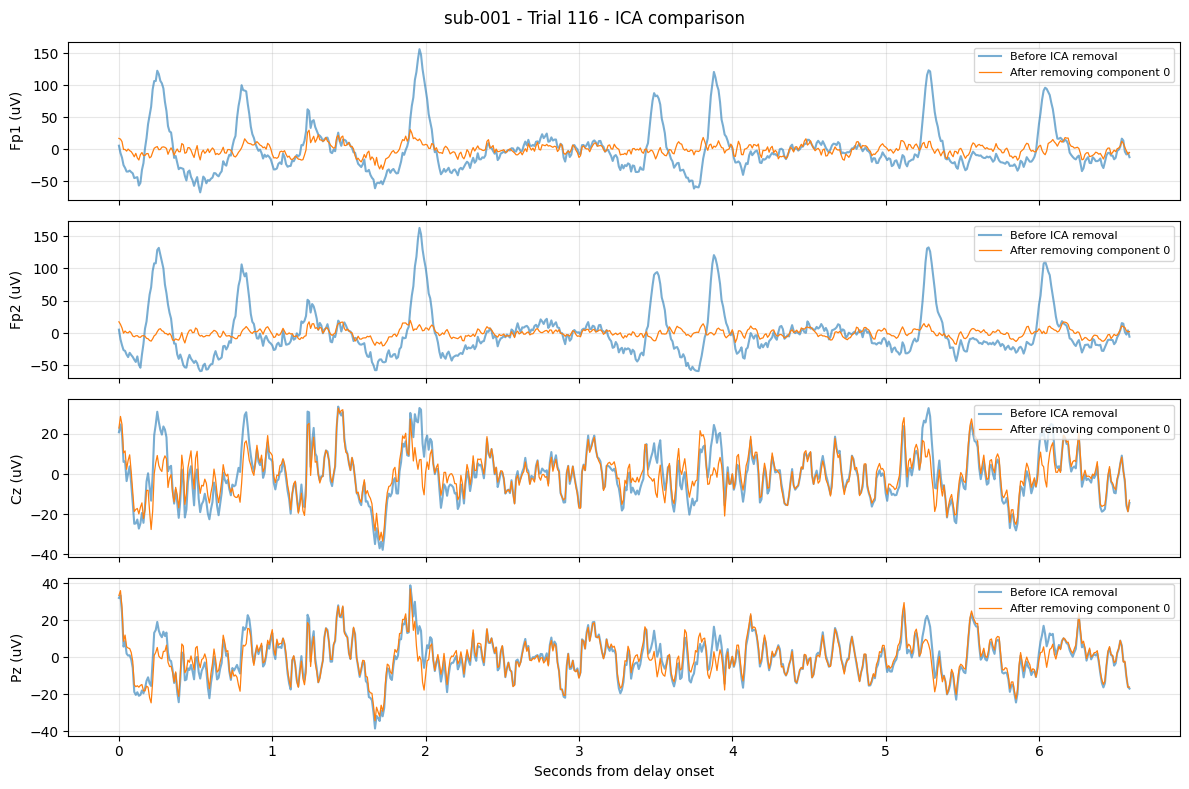

Median results across all 120 trials:


,ptp_before_uV,ptp_after_uV,abs_EOG_r_before,abs_EOG_r_after
channel,,,,
Cz,65.851,55.549,0.446,0.073
Fp1,172.215,45.352,0.877,0.107
Fp2,182.562,35.017,0.896,0.059
Pz,57.601,52.788,0.312,0.074


Trial 116:


,trial_number,channel,ptp_before_uV,ptp_after_uV,abs_EOG_r_before,abs_EOG_r_after
460,116,Fp1,223.415,61.900,0.728,0.057
461,116,Fp2,221.875,39.443,0.746,0.107
462,116,Cz,71.405,66.331,0.247,0.186
463,116,Pz,77.459,71.313,0.018,0.295


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Keep the fitted model and filtered recording for comparison.
ica_sub001 = ica.copy()
ica_sub001.exclude = [0]

before_sub001 = raw_ica
cleaned_sub001 = raw_ica.copy()

# Remove candidate component 0 from the copy.
ica_sub001.apply(cleaned_sub001, verbose="ERROR")

channels = ["Fp1", "Fp2", "Cz", "Pz"]
fs = float(before_sub001.info["sfreq"])
comparison_rows = []

# Compare every trial, not only trial 116.
for trial in subject_trials.itertuples(index=False):
    start = int(round(
        (trial.delay_onset - before_sub001.first_time) * fs
    ))
    stop = int(round(
        (trial.probe_onset - before_sub001.first_time) * fs
    ))

    if not 0 <= start < stop <= before_sub001.n_times:
        raise ValueError("Invalid timing for trial " + str(trial.trial_number))

    before = before_sub001.get_data(
        picks=channels, start=start, stop=stop
    )
    after = cleaned_sub001.get_data(
        picks=channels, start=start, stop=stop
    )
    eog = before_sub001.get_data(
        picks=["EOGv"], start=start, stop=stop
    )[0]

    for index, channel in enumerate(channels):
        r_before = np.nan
        r_after = np.nan

        if eog.std() > 0 and before[index].std() > 0:
            r_before = np.corrcoef(before[index], eog)[0, 1]

        if eog.std() > 0 and after[index].std() > 0:
            r_after = np.corrcoef(after[index], eog)[0, 1]

        comparison_rows.append({
            "trial_number": trial.trial_number,
            "channel": channel,
            "ptp_before_uV": np.ptp(before[index]) * 1e6,
            "ptp_after_uV": np.ptp(after[index]) * 1e6,
            "abs_EOG_r_before": abs(r_before),
            "abs_EOG_r_after": abs(r_after)
        })

    if trial.trial_number == 116:
        times = np.arange(before.shape[1]) / fs
        fig, axes = plt.subplots(
            4, 1, figsize=(12, 8), sharex=True
        )

        for index, channel in enumerate(channels):
            axes[index].plot(
                times, before[index] * 1e6,
                alpha=0.6, label="Before ICA removal"
            )
            axes[index].plot(
                times, after[index] * 1e6,
                linewidth=0.9, label="After removing component 0"
            )
            axes[index].set_ylabel(channel + " (uV)")
            axes[index].legend(loc="upper right", fontsize=8)
            axes[index].grid(alpha=0.3)

        axes[-1].set_xlabel("Seconds from delay onset")
        fig.suptitle("sub-001 - Trial 116 - ICA comparison")
        fig.tight_layout()
        plt.show()
        plt.close(fig)

ica_comparison_sub001 = pd.DataFrame(comparison_rows)

print("Median results across all 120 trials:")
display(
    ica_comparison_sub001.groupby("channel")[
        [
            "ptp_before_uV",
            "ptp_after_uV",
            "abs_EOG_r_before",
            "abs_EOG_r_after"
        ]
    ].median().round(3)
)

print("Trial 116:")
display(
    ica_comparison_sub001[
        ica_comparison_sub001["trial_number"] == 116
    ].round(3)
)

In [3]:
%pip install mne numpy pandas scipy scikit-learn matplotlib requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 17.1 MB/s  0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mne]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [1]:
from pathlib import Path
import mne

print("MNE version:", mne.__version__)
print(
    "Project folder exists:",
    Path("/content/federated-eeg-working-memory").is_dir()
)
print(
    "Raw EEG exists:",
    Path(
        "/content/federated-eeg-working-memory/data/sub-001/eeg/"
        "sub-001_task-VerbalWorkingMemory_eeg.set"
    ).is_file()
)

for name in ["ica_sub001", "cleaned_sub001", "ica_comparison_sub001"]:
    print(name, "available:", name in globals())

MNE version: 1.13.2
Project folder exists: False
Raw EEG exists: False
ica_sub001 available: False
cleaned_sub001 available: False
ica_comparison_sub001 available: False


In [2]:
from google.colab import drive
from pathlib import Path
import subprocess
import os

drive.mount("/content/drive")

project = Path("/content/federated-eeg-working-memory")

if not project.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/EmanAdil122/federated-eeg-working-memory.git",
            str(project)
        ],
        check=True
    )

os.chdir(project)
print("Project restored:", project)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project restored: /content/federated-eeg-working-memory


In [4]:
from pathlib import Path
from datetime import datetime, timezone
import warnings
import json

import mne
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
drive_root = Path("/content/drive/MyDrive")

if not drive_root.is_dir():
    raise RuntimeError("Pehle Google Drive mount karo.")

trials = pd.read_csv(project / "reports/trial_table.csv")
subject_trials = trials[
    trials["participant_id"] == "sub-001"
].copy()

eeg_file = next(
    (project / "data/sub-001/eeg").glob("*_eeg.set")
)

raw_ica = mne.io.read_raw_eeglab(
    eeg_file, preload=False, verbose="ERROR"
)
raw_ica.set_channel_types({"EOGv": "eog", "EOGh": "eog"})

start_time = max(
    0, float(subject_trials["delay_onset"].min()) - 10
)
end_time = min(
    raw_ica.times[-1],
    float(subject_trials["probe_onset"].max()) + 10
)

raw_ica.crop(tmin=start_time, tmax=end_time).load_data()

eeg = raw_ica.get_data(picks="eeg")
if not np.isfinite(eeg).all():
    raise ValueError("Non-finite EEG samples found.")
if (np.abs(eeg) * 1e6 >= 10239.0).any():
    raise ValueError("Boundary-level samples found. Review before ICA.")
del eeg

print("Applying filters...", flush=True)

picks = mne.pick_types(
    raw_ica.info, eeg=True, eog=True, exclude=[]
)

raw_ica.notch_filter(
    freqs=[50], picks=picks, method="iir", verbose="ERROR"
)
raw_ica.filter(
    l_freq=1,
    h_freq=40,
    picks=picks,
    method="iir",
    iir_params={"order": 4, "ftype": "butter"},
    verbose="ERROR"
)
raw_ica.resample(100, verbose="ERROR")

ica = mne.preprocessing.ICA(
    n_components=0.99,
    method="fastica",
    random_state=42,
    max_iter=1000
)

print("Restoring ICA fit...", flush=True)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    ica.fit(raw_ica, picks="eeg", verbose="ERROR")

if any(issubclass(w.category, ConvergenceWarning) for w in caught):
    raise RuntimeError("ICA did not converge. Share this output.")

scores = ica.score_sources(
    raw_ica,
    target="EOGv",
    score_func="pearsonr",
    verbose="ERROR"
)

component_table = pd.DataFrame({
    "component": np.arange(len(scores)),
    "EOGv_correlation": scores,
    "absolute_correlation": np.abs(scores)
}).sort_values("absolute_correlation", ascending=False)

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
restore_folder = (
    drive_root / "EEG_Project" / "checkpoints"
    / ("sub-001_ICA_restored_" + stamp)
)
restore_folder.mkdir(parents=True, exist_ok=False)

ica.save(restore_folder / "sub-001-ica.fif", overwrite=False)
raw_ica.save(
    restore_folder / "sub-001_filtered_raw.fif",
    overwrite=False
)
component_table.to_csv(
    restore_folder / "component_scores.csv", index=False
)
subject_trials.to_csv(
    restore_folder / "trial_table.csv", index=False
)

settings = {
    "participant": "sub-001",
    "status": "filtered recording and fitted ICA; no components removed",
    "bandpass_Hz": [1, 40],
    "notch_Hz": 50,
    "sampling_rate_Hz": 100,
    "ica_method": "fastica",
    "ica_variance_setting": 0.99,
    "random_state": 42,
    "reference": "original linked earlobes retained",
    "mne_version": mne.__version__
}

with (restore_folder / "settings.json").open("w") as file:
    json.dump(settings, file, indent=2)

print("ICA components:", ica.n_components_)
print("Iterations:", ica.n_iter_)
display(component_table.round(3))
print("Checkpoint saved:", restore_folder)

Reading 0 ... 1222990  =      0.000 ...  2445.980 secs...
Applying filters...
Use rng= instead of random_state= in new code
Restoring ICA fit...
Writing ICA solution to /content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC/sub-001-ica.fif...
Writing /content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC/sub-001_filtered_raw.fif
Closing /content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC/sub-001_filtered_raw.fif
[done]
ICA components: 12
Iterations: 22


,component,EOGv_correlation,absolute_correlation
0,0,0.856,0.856
4,4,-0.131,0.131
5,5,-0.124,0.124
1,1,-0.071,0.071
2,2,0.061,0.061
9,9,-0.057,0.057
11,11,0.038,0.038
8,8,0.034,0.034
7,7,-0.024,0.024
3,3,0.024,0.024


Checkpoint saved: /content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC


In [5]:
import json
import numpy as np
import pandas as pd
from IPython.display import display

ica_sub001 = ica.copy()
ica_sub001.exclude = [0]

before_sub001 = raw_ica
cleaned_sub001 = raw_ica.copy()
ica_sub001.apply(cleaned_sub001, verbose="ERROR")

if not np.isfinite(cleaned_sub001.get_data()).all():
    raise ValueError("Non-finite values found after ICA correction.")

channels = ["Fp1", "Fp2", "Cz", "Pz"]
fs = float(raw_ica.info["sfreq"])
rows = []

for trial in subject_trials.itertuples(index=False):
    start = int(round(
        (trial.delay_onset - raw_ica.first_time) * fs
    ))
    stop = int(round(
        (trial.probe_onset - raw_ica.first_time) * fs
    ))

    if not 0 <= start < stop <= raw_ica.n_times:
        raise ValueError("Invalid trial timing.")

    before = raw_ica.get_data(
        picks=channels, start=start, stop=stop
    )
    after = cleaned_sub001.get_data(
        picks=channels, start=start, stop=stop
    )
    eog = raw_ica.get_data(
        picks=["EOGv"], start=start, stop=stop
    )[0]

    for index, channel in enumerate(channels):
        row = {
            "trial_number": trial.trial_number,
            "channel": channel,
            "ptp_before_uV": np.ptp(before[index]) * 1e6,
            "ptp_after_uV": np.ptp(after[index]) * 1e6
        }

        for label, values in [
            ("before", before[index]),
            ("after", after[index])
        ]:
            correlation = np.nan
            if values.std() > 0 and eog.std() > 0:
                correlation = abs(np.corrcoef(values, eog)[0, 1])
            row["abs_EOG_r_" + label] = correlation

        rows.append(row)

ica_comparison_sub001 = pd.DataFrame(rows)

# Re-running this cell replaces only these derived checkpoint files.
ica_sub001.save(
    restore_folder / "sub-001_reviewed-ica.fif",
    overwrite=True
)
cleaned_sub001.save(
    restore_folder / "sub-001_cleaned_raw.fif",
    overwrite=True
)
ica_comparison_sub001.to_csv(
    restore_folder / "ica_before_after_comparison.csv",
    index=False
)

decision = {
    "participant": "sub-001",
    "excluded_components": [0],
    "reason": (
        "EOGv correlation 0.856, frontal template scalp pattern, "
        "matching eye-event timing and reviewed before/after waveforms"
    ),
    "status": "pilot ICA correction saved; final feature checks pending",
    "sampling_rate_Hz": fs
}
with (restore_folder / "ica_decision.json").open("w") as file:
    json.dump(decision, file, indent=2)

print("Median comparison across 120 trials:")
display(
    ica_comparison_sub001.groupby("channel")[
        [
            "ptp_before_uV",
            "ptp_after_uV",
            "abs_EOG_r_before",
            "abs_EOG_r_after"
        ]
    ].median().round(3)
)

print("Corrected recording and reviewed ICA saved:")
print(restore_folder)

Writing ICA solution to /content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC/sub-001_reviewed-ica.fif...
Writing /content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC/sub-001_cleaned_raw.fif
Closing /content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC/sub-001_cleaned_raw.fif
[done]
Median comparison across 120 trials:


,ptp_before_uV,ptp_after_uV,abs_EOG_r_before,abs_EOG_r_after
channel,,,,
Cz,65.851,55.549,0.446,0.073
Fp1,172.215,45.352,0.877,0.107
Fp2,182.562,35.017,0.896,0.059
Pz,57.601,52.788,0.312,0.074


Corrected recording and reviewed ICA saved:
/content/drive/MyDrive/EEG_Project/checkpoints/sub-001_ICA_restored_20261107_184916_UTC


In [6]:
from pathlib import Path
from datetime import datetime, timezone
import warnings
import json

import mne
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
drive_root = Path("/content/drive/MyDrive")

if not drive_root.is_dir():
    raise RuntimeError("Pehle Google Drive mount karo.")

trials = pd.read_csv(project / "reports/trial_table.csv")
trials_sub002 = trials[
    trials["participant_id"] == "sub-002"
].copy()

eeg_file = next(
    (project / "data/sub-002/eeg").glob("*_eeg.set")
)

raw_sub002 = mne.io.read_raw_eeglab(
    eeg_file, preload=False, verbose="ERROR"
)
raw_sub002.set_channel_types({"EOGv": "eog", "EOGh": "eog"})

start_time = max(
    0, float(trials_sub002["delay_onset"].min()) - 10
)
end_time = min(
    raw_sub002.times[-1],
    float(trials_sub002["probe_onset"].max()) + 10
)

raw_sub002.crop(tmin=start_time, tmax=end_time).load_data()

eeg = raw_sub002.get_data(picks="eeg")

if not np.isfinite(eeg).all():
    raise ValueError("Non-finite EEG samples found.")

if (np.abs(eeg) * 1e6 >= 10239.0).any():
    raise ValueError("Boundary-level samples found. Review before ICA.")

del eeg

print("Applying filters to sub-002...", flush=True)

picks = mne.pick_types(
    raw_sub002.info, eeg=True, eog=True, exclude=[]
)

raw_sub002.notch_filter(
    freqs=[50], picks=picks, method="iir", verbose="ERROR"
)
raw_sub002.filter(
    l_freq=1,
    h_freq=40,
    picks=picks,
    method="iir",
    iir_params={"order": 4, "ftype": "butter"},
    verbose="ERROR"
)
raw_sub002.resample(100, verbose="ERROR")

ica_sub002 = mne.preprocessing.ICA(
    n_components=0.99,
    method="fastica",
    random_state=42,
    max_iter=1000
)

print("Fitting sub-002 ICA...", flush=True)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    ica_sub002.fit(raw_sub002, picks="eeg", verbose="ERROR")

if any(issubclass(w.category, ConvergenceWarning) for w in caught):
    raise RuntimeError("ICA did not converge. Share this output.")

scores_sub002 = ica_sub002.score_sources(
    raw_sub002,
    target="EOGv",
    score_func="pearsonr",
    verbose="ERROR"
)

components_sub002 = pd.DataFrame({
    "component": np.arange(len(scores_sub002)),
    "EOGv_correlation": scores_sub002,
    "absolute_correlation": np.abs(scores_sub002)
}).sort_values("absolute_correlation", ascending=False)

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
folder_sub002 = (
    drive_root / "EEG_Project" / "checkpoints"
    / ("sub-002_ICA_" + stamp)
)
folder_sub002.mkdir(parents=True, exist_ok=False)

ica_sub002.save(
    folder_sub002 / "sub-002-ica.fif",
    overwrite=False
)
raw_sub002.save(
    folder_sub002 / "sub-002_filtered_raw.fif",
    overwrite=False
)
components_sub002.to_csv(
    folder_sub002 / "component_scores.csv",
    index=False
)
trials_sub002.to_csv(
    folder_sub002 / "trial_table.csv",
    index=False
)

settings = {
    "participant": "sub-002",
    "status": "filtered recording and fitted ICA; component review pending",
    "bandpass_Hz": [1, 40],
    "notch_Hz": 50,
    "sampling_rate_Hz": 100,
    "ica_method": "fastica",
    "ica_variance_setting": 0.99,
    "random_state": 42,
    "excluded_components": [],
    "reference": "original linked earlobes retained",
    "mne_version": mne.__version__
}

with (folder_sub002 / "settings.json").open("w") as file:
    json.dump(settings, file, indent=2)

print("ICA components:", ica_sub002.n_components_)
print("Iterations:", ica_sub002.n_iter_)
display(components_sub002.round(3))
print("Checkpoint saved:", folder_sub002)

Reading 0 ... 1223215  =      0.000 ...  2446.430 secs...
Applying filters to sub-002...
Use rng= instead of random_state= in new code
Fitting sub-002 ICA...
Writing ICA solution to /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC/sub-002-ica.fif...
Writing /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC/sub-002_filtered_raw.fif
Closing /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC/sub-002_filtered_raw.fif
[done]
ICA components: 15
Iterations: 52


,component,EOGv_correlation,absolute_correlation
1,1,-0.478,0.478
0,0,-0.467,0.467
5,5,-0.120,0.120
3,3,-0.088,0.088
2,2,-0.071,0.071
12,12,0.047,0.047
10,10,-0.046,0.046
7,7,-0.042,0.042
4,4,-0.032,0.032
6,6,-0.032,0.032


Checkpoint saved: /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC


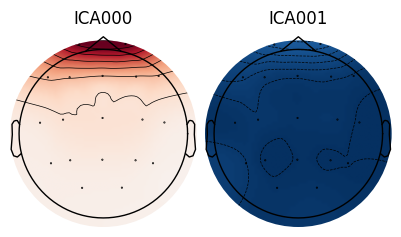

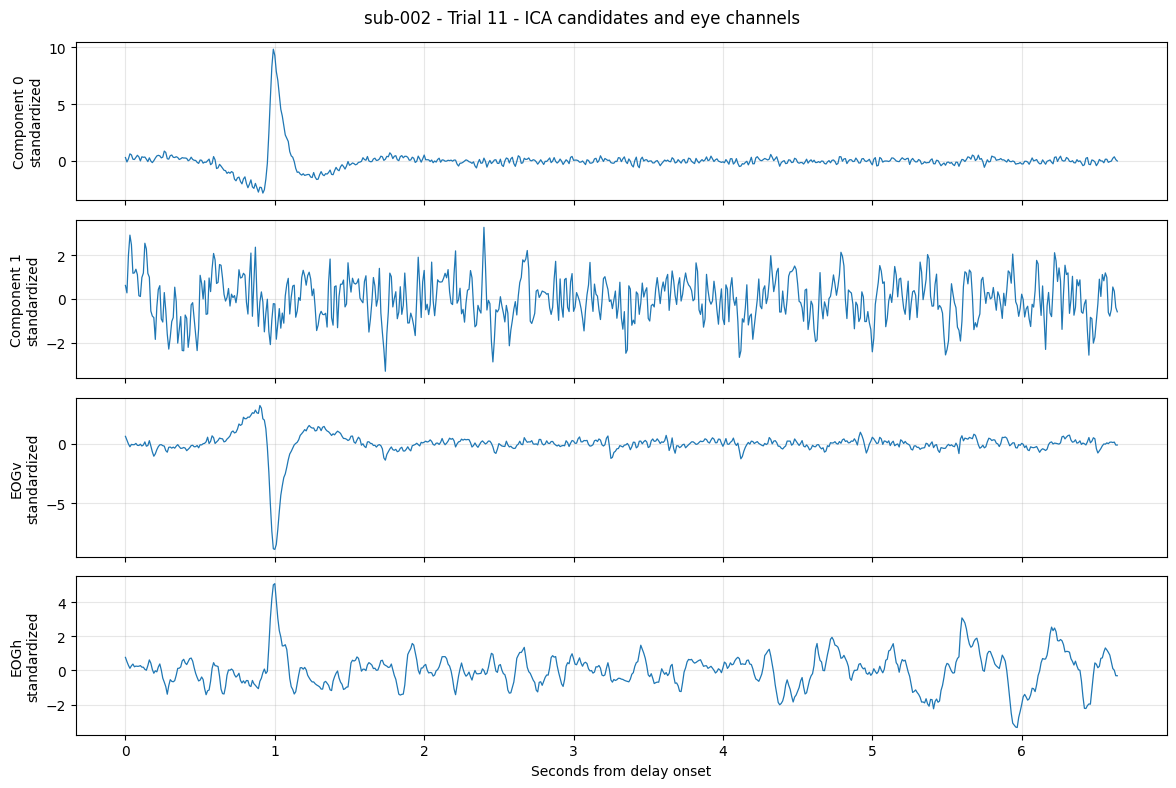

In [7]:
import mne
import numpy as np
import matplotlib.pyplot as plt

# Approximate standard positions for scalp visualization.
montage = mne.channels.make_standard_montage("colin27_1020")

ica_plot_sub002 = ica_sub002.copy()
ica_plot_sub002.info.set_montage(
    montage,
    match_case=False,
    on_missing="raise"
)

ica_plot_sub002.plot_components(picks=[0, 1], show=True)

# Inspect the two candidates alongside both eye channels.
trial = trials_sub002[
    trials_sub002["trial_number"] == 11
].iloc[0]

fs = float(raw_sub002.info["sfreq"])

start = int(round(
    (float(trial["delay_onset"]) - raw_sub002.first_time) * fs
))
stop = int(round(
    (float(trial["probe_onset"]) - raw_sub002.first_time) * fs
))

if not 0 <= start < stop <= raw_sub002.n_times:
    raise ValueError("Trial timing is outside the recording.")

sources_sub002 = ica_sub002.get_sources(raw_sub002)

components = sources_sub002.get_data(
    picks=[0, 1],
    start=start,
    stop=stop
)

eye_signals = raw_sub002.get_data(
    picks=["EOGv", "EOGh"],
    start=start,
    stop=stop
)

signals = [
    components[0],
    components[1],
    eye_signals[0],
    eye_signals[1]
]
labels = ["Component 0", "Component 1", "EOGv", "EOGh"]
times = np.arange(components.shape[1]) / fs

fig, axes = plt.subplots(
    4, 1, figsize=(12, 8), sharex=True
)

for axis, values, label in zip(axes, signals, labels):
    centered = values - values.mean()
    spread = values.std()
    standardized = centered / spread if spread > 0 else centered

    axis.plot(times, standardized, linewidth=0.9)
    axis.set_ylabel(label + "\nstandardized")
    axis.grid(alpha=0.3)

axes[-1].set_xlabel("Seconds from delay onset")
fig.suptitle("sub-002 - Trial 11 - ICA candidates and eye channels")
fig.tight_layout()
plt.show()
plt.close(fig)

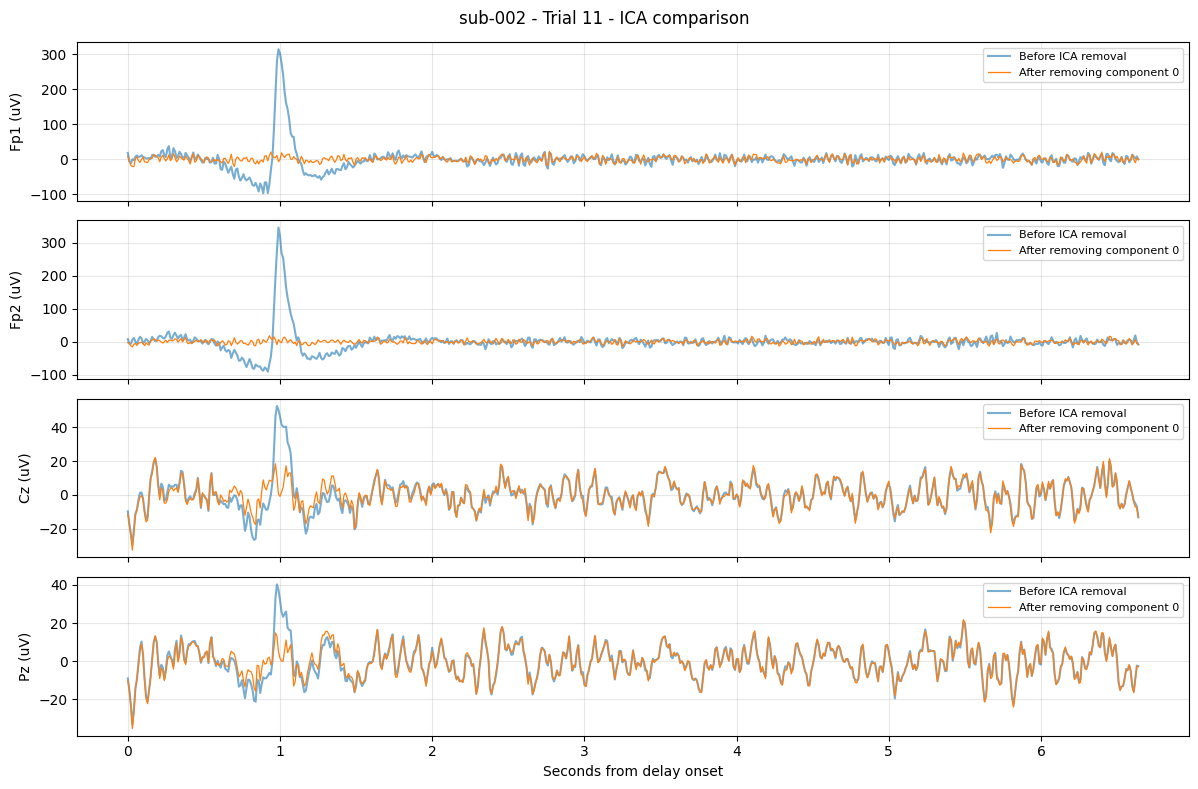

Writing ICA solution to /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC/sub-002_candidate-ica.fif...
Writing /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC/sub-002_candidate_raw.fif
Closing /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC/sub-002_candidate_raw.fif
[done]
Median comparison across 120 trials:


,ptp_before_uV,ptp_after_uV,abs_EOG_r_before,abs_EOG_r_after
channel,,,,
Cz,55.916,55.721,0.168,0.113
Fp1,63.634,51.139,0.368,0.182
Fp2,57.157,37.648,0.307,0.081
Pz,56.851,56.636,0.066,0.061


Trial 11:


,trial_number,channel,ptp_before_uV,ptp_after_uV,abs_EOG_r_before,abs_EOG_r_after
40,11,Fp1,412.494,43.338,0.897,0.105
41,11,Fp2,437.404,34.546,0.910,0.073
42,11,Cz,82.128,54.917,0.595,0.138
43,11,Pz,73.317,56.947,0.474,0.145


Candidate correction saved: /content/drive/MyDrive/EEG_Project/checkpoints/sub-002_ICA_20261107_185415_UTC


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ica_sub002_candidate = ica_sub002.copy()
ica_sub002_candidate.exclude = [0]

cleaned_sub002_candidate = raw_sub002.copy()
ica_sub002_candidate.apply(
    cleaned_sub002_candidate, verbose="ERROR"
)

channels = ["Fp1", "Fp2", "Cz", "Pz"]
fs = float(raw_sub002.info["sfreq"])
rows = []

for trial in trials_sub002.itertuples(index=False):
    start = int(round(
        (trial.delay_onset - raw_sub002.first_time) * fs
    ))
    stop = int(round(
        (trial.probe_onset - raw_sub002.first_time) * fs
    ))

    if not 0 <= start < stop <= raw_sub002.n_times:
        raise ValueError("Invalid trial timing.")

    before = raw_sub002.get_data(
        picks=channels, start=start, stop=stop
    )
    after = cleaned_sub002_candidate.get_data(
        picks=channels, start=start, stop=stop
    )
    eog = raw_sub002.get_data(
        picks=["EOGv"], start=start, stop=stop
    )[0]

    if not np.isfinite(after).all():
        raise ValueError("Non-finite samples after correction.")

    for index, channel in enumerate(channels):
        row = {
            "trial_number": trial.trial_number,
            "channel": channel,
            "ptp_before_uV": np.ptp(before[index]) * 1e6,
            "ptp_after_uV": np.ptp(after[index]) * 1e6
        }

        for label, values in [
            ("before", before[index]),
            ("after", after[index])
        ]:
            correlation = np.nan
            if values.std() > 0 and eog.std() > 0:
                correlation = abs(np.corrcoef(values, eog)[0, 1])
            row["abs_EOG_r_" + label] = correlation

        rows.append(row)

    if trial.trial_number == 11:
        times = np.arange(before.shape[1]) / fs
        fig, axes = plt.subplots(
            4, 1, figsize=(12, 8), sharex=True
        )

        for index, channel in enumerate(channels):
            axes[index].plot(
                times, before[index] * 1e6,
                alpha=0.6, label="Before ICA removal"
            )
            axes[index].plot(
                times, after[index] * 1e6,
                linewidth=0.9, label="After removing component 0"
            )
            axes[index].set_ylabel(channel + " (uV)")
            axes[index].legend(loc="upper right", fontsize=8)
            axes[index].grid(alpha=0.3)

        axes[-1].set_xlabel("Seconds from delay onset")
        fig.suptitle("sub-002 - Trial 11 - ICA comparison")
        fig.tight_layout()
        plt.show()
        plt.close(fig)

ica_comparison_sub002 = pd.DataFrame(rows)

# Save candidate results immediately for recovery.
ica_comparison_sub002.to_csv(
    folder_sub002 / "candidate_ica_comparison.csv",
    index=False
)
ica_sub002_candidate.save(
    folder_sub002 / "sub-002_candidate-ica.fif",
    overwrite=True
)
cleaned_sub002_candidate.save(
    folder_sub002 / "sub-002_candidate_raw.fif",
    overwrite=True
)

print("Median comparison across 120 trials:")
display(
    ica_comparison_sub002.groupby("channel")[
        [
            "ptp_before_uV",
            "ptp_after_uV",
            "abs_EOG_r_before",
            "abs_EOG_r_after"
        ]
    ].median().round(3)
)

print("Trial 11:")
display(
    ica_comparison_sub002[
        ica_comparison_sub002["trial_number"] == 11
    ].round(3)
)

print("Candidate correction saved:", folder_sub002)

In [9]:
import json
import numpy as np
import pandas as pd
from IPython.display import display

# Retain the reviewed sub-002 correction.
cleaned_sub002 = cleaned_sub002_candidate
ica_sub002_reviewed = ica_sub002_candidate.copy()

decision = {
    "participant": "sub-002",
    "excluded_components": [0],
    "retained_candidate_components": [1],
    "reason": (
        "Component 0 had a frontal pattern, matching eye-event timing "
        "and supportive before/after waveform and correlation results."
    ),
    "recording_file": "sub-002_candidate_raw.fif",
    "ica_file": "sub-002_candidate-ica.fif",
    "status": "reviewed pilot correction; final feature checks pending"
}

with (folder_sub002 / "ica_decision.json").open("w") as file:
    json.dump(decision, file, indent=2)

recordings = {
    "sub-001": cleaned_sub001,
    "sub-002": cleaned_sub002
}

quality_rows = []

for participant, recording in recordings.items():
    subject_rows = trials[
        trials["participant_id"] == participant
    ].sort_values("trial_number")

    eeg_names = [
        name for name, channel_type in zip(
            recording.ch_names, recording.get_channel_types()
        )
        if channel_type == "eeg"
    ]
    if len(eeg_names) != 19:
        raise ValueError("Unexpected EEG channel count: " + participant)

    fs = float(recording.info["sfreq"])

    for trial in subject_rows.itertuples(index=False):
        start = int(round(
            (trial.delay_onset - recording.first_time) * fs
        ))
        stop = int(round(
            (trial.probe_onset - recording.first_time) * fs
        ))

        if not 0 <= start < stop <= recording.n_times:
            raise ValueError("Invalid window: " + participant)

        signal = recording.get_data(
            picks=eeg_names, start=start, stop=stop
        ) * 1e6

        finite = bool(np.isfinite(signal).all())
        if not finite:
            raise ValueError("Non-finite samples: " + participant)

        ranges = np.ptp(signal, axis=1)

        quality_rows.append({
            "participant_id": participant,
            "trial_number": trial.trial_number,
            "condition": trial.condition,
            "eeg_channels": len(eeg_names),
            "samples": signal.shape[1],
            "max_ptp_uV": float(ranges.max()),
            "largest_channel": eeg_names[int(ranges.argmax())],
            "flat_channels": int((ranges < 0.1).sum()),
            "over_500uV_review": bool((ranges > 500).any())
        })

final_quality = pd.DataFrame(quality_rows)

if len(final_quality) != 240:
    raise ValueError("Expected 240 trial rows.")

if final_quality.duplicated(["participant_id", "trial_number"]).any():
    raise ValueError("Duplicate participant/trial IDs found.")

final_quality.to_csv(
    project / "reports/final_pilot_signal_quality.csv",
    index=False
)

# Save the combined audit in both participant checkpoints.
for destination in [restore_folder, folder_sub002]:
    final_quality.to_csv(
        destination / "final_pilot_signal_quality.csv",
        index=False
    )

print("Quality summary:")
display(
    final_quality.groupby("participant_id").agg(
        trials=("trial_number", "size"),
        median_max_ptp_uV=("max_ptp_uV", "median"),
        highest_ptp_uV=("max_ptp_uV", "max"),
        trials_over_500uV=("over_500uV_review", "sum"),
        flat_channel_count=("flat_channels", "sum")
    ).round(3)
)

print("Ten highest-amplitude trials:")
display(
    final_quality.nlargest(10, "max_ptp_uV")
    .reset_index(drop=True).round(3)
)

print("Review decision and quality audit saved to Drive.")

Quality summary:


,trials,median_max_ptp_uV,highest_ptp_uV,trials_over_500uV,flat_channel_count
participant_id,,,,,
sub-001,120,67.458,142.577,0,0
sub-002,120,66.930,249.077,0,0


Ten highest-amplitude trials:


,participant_id,trial_number,condition,eeg_channels,samples,max_ptp_uV,largest_channel,flat_channels,over_500uV_review
0,sub-002,15,6M,19,668,249.077,F7,0,False
1,sub-002,77,6R,19,660,151.637,Pz,0,False
2,sub-002,80,6R,19,670,150.075,Pz,0,False
3,sub-001,53,6R,19,660,142.577,P3,0,False
4,sub-001,117,7M,19,670,129.743,F7,0,False
5,sub-002,83,5M,19,660,125.672,Pz,0,False
6,sub-002,78,6R,19,660,110.135,Pz,0,False
7,sub-001,65,5M,19,660,108.709,P3,0,False
8,sub-001,5,6M,19,665,108.452,T4,0,False
9,sub-002,79,6R,19,670,105.882,Pz,0,False


Review decision and quality audit saved to Drive.


In [10]:
import json
import numpy as np
import pandas as pd
from scipy.signal import welch
from IPython.display import display

bands = {
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0)
}

recordings = {
    "sub-001": cleaned_sub001,
    "sub-002": cleaned_sub002
}

feature_rows = []

for participant, recording in recordings.items():
    print("Extracting features:", participant, flush=True)

    eeg_names = [
        name for name, channel_type in zip(
            recording.ch_names, recording.get_channel_types()
        )
        if channel_type == "eeg"
    ]

    if len(eeg_names) != 19:
        raise ValueError("Expected 19 EEG channels.")

    fs = float(recording.info["sfreq"])
    participant_trials = trials[
        trials["participant_id"] == participant
    ].sort_values("trial_number")

    for trial in participant_trials.itertuples(index=False):
        start = int(round(
            (trial.delay_onset - recording.first_time) * fs
        ))
        stop = int(round(
            (trial.probe_onset - recording.first_time) * fs
        ))

        if not 0 <= start < stop <= recording.n_times:
            raise ValueError("Invalid feature window.")

        signal_uv = recording.get_data(
            picks=eeg_names, start=start, stop=stop
        ) * 1e6

        if not np.isfinite(signal_uv).all():
            raise ValueError("Non-finite signal in feature window.")

        frequencies, psd = welch(
            signal_uv,
            fs=fs,
            window="hann",
            nperseg=int(2 * fs),
            noverlap=int(fs),
            detrend="constant",
            scaling="density",
            axis=-1
        )

        row = {
            "participant_id": participant,
            "trial_number": trial.trial_number,
            "condition": trial.condition,
            "delay_onset": trial.delay_onset,
            "probe_onset": trial.probe_onset,
            "window_duration_seconds": signal_uv.shape[1] / fs
        }

        for channel_index, channel in enumerate(eeg_names):
            for band, (low, high) in bands.items():
                selected = (
                    (frequencies >= low) & (frequencies <= high)
                )
                row[channel + "_" + band + "_power"] = float(
                    np.trapezoid(
                        psd[channel_index, selected],
                        frequencies[selected]
                    )
                )

        feature_rows.append(row)

features = pd.DataFrame(feature_rows)
feature_columns = [
    column for column in features.columns
    if column.endswith("_power")
]

if len(features) != 240 or len(feature_columns) != 57:
    raise ValueError("Expected 240 trials and 57 band-power features.")

if features.duplicated(["participant_id", "trial_number"]).any():
    raise ValueError("Duplicate participant/trial IDs.")

values = features[feature_columns].to_numpy()
if not np.isfinite(values).all() or (values < 0).any():
    raise ValueError("Invalid band-power values.")

# Preserve the final numerical quality audit.
features = features.merge(
    final_quality[
        [
            "participant_id",
            "trial_number",
            "max_ptp_uV",
            "flat_channels",
            "over_500uV_review"
        ]
    ],
    on=["participant_id", "trial_number"],
    how="left",
    validate="one_to_one"
)

filename = "eeg_features_cleaned_signal.csv"

for destination in [
    project / "reports",
    restore_folder,
    folder_sub002
]:
    features.to_csv(destination / filename, index=False)

schema = {
    "feature_columns": feature_columns,
    "power_units": "microvolt squared",
    "bands_Hz": bands,
    "welch_window_seconds": 2,
    "welch_overlap_seconds": 1,
    "integration": "trapezoidal; both band endpoints included",
    "source": "1-40 Hz filtered, 100 Hz, reviewed ICA-corrected pilot data"
}

with (restore_folder / "feature_schema.json").open("w") as file:
    json.dump(schema, file, indent=2)

with (folder_sub002 / "feature_schema.json").open("w") as file:
    json.dump(schema, file, indent=2)

print("Trial rows:", len(features))
print("Band-power features:", len(feature_columns))
print("Missing feature values:", features[feature_columns].isna().sum().sum())
display(features.head())
print("Saved locally and in both Drive checkpoints.")

Extracting features: sub-001
Extracting features: sub-002
Trial rows: 240
Band-power features: 57
Missing feature values: 0


,participant_id,trial_number,condition,delay_onset,probe_onset,window_duration_seconds,Fp1_theta_power,Fp1_alpha_power,Fp1_beta_power,Fp2_theta_power,...,T6_beta_power,O1_theta_power,O1_alpha_power,O1_beta_power,O2_theta_power,O2_alpha_power,O2_beta_power,max_ptp_uV,flat_channels,over_500uV_review
0,sub-001,1,6M,639.12,645.76,6.64,9.556578,5.403907,11.170174,9.289398,...,33.450262,9.351852,12.841188,24.040753,13.567920,11.454573,23.711932,98.680449,0,False
1,sub-001,2,6M,659.34,666.01,6.67,11.127604,7.000520,9.162734,7.756595,...,25.086028,3.725935,9.325904,15.010088,5.091734,9.879994,17.087291,82.916499,0,False
2,sub-001,3,6M,679.77,686.45,6.68,20.097434,7.151660,7.871307,11.498828,...,38.600735,8.863061,21.848315,21.478242,9.454956,12.130986,24.400738,82.410900,0,False
3,sub-001,4,6M,699.93,706.58,6.65,13.484522,5.767467,9.455008,8.663864,...,21.017361,8.233483,7.362718,16.829051,7.009341,9.028511,17.630000,91.289585,0,False
4,sub-001,5,6M,720.38,727.03,6.65,11.667277,6.410318,8.082961,11.009475,...,22.578972,6.288619,9.759372,17.373838,8.735810,15.230637,17.292940,108.451710,0,False


Saved locally and in both Drive checkpoints.


In [11]:
import json
import pandas as pd
from IPython.display import display

features = pd.read_csv(
    project / "reports/eeg_features_cleaned_signal.csv"
)

condition_mapping = {
    "5R": 0, "6R": 1, "7R": 2,
    "5M": 3, "6M": 4, "7M": 5
}
task_mapping = {"R": 0, "M": 1}

if not features["condition"].isin(condition_mapping).all():
    raise ValueError("Missing or unexpected condition labels.")

encoded = features.copy()
encoded["condition_encoded"] = encoded["condition"].map(
    condition_mapping
).astype(int)
encoded["load_level"] = encoded["condition"].str[0].astype(int)
encoded["task_type"] = encoded["condition"].str[1]
encoded["task_type_encoded"] = encoded["task_type"].map(task_mapping)

# Preserve the provisional response audit separately from target labels.
response_audit = pd.read_csv(
    project / "reports/response_probe_audit.csv"
)

audit_columns = [
    "participant_id", "trial_number", "condition", "probe_onset",
    "response_count", "response_labels", "response_delays_s",
    "status", "issues"
]

encoded = encoded.merge(
    response_audit[audit_columns],
    on=["participant_id", "trial_number"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_audit")
)

if encoded["status"].isna().any():
    raise ValueError("Some trials have no matching response audit.")

if not encoded["condition"].eq(encoded["condition_audit"]).all():
    raise ValueError("Condition mismatch between features and audit.")

if ((encoded["probe_onset"] - encoded["probe_onset_audit"]).abs() > 0.001).any():
    raise ValueError("Probe timing mismatch between features and audit.")

encoded = encoded.drop(
    columns=["condition_audit", "probe_onset_audit"]
).rename(columns={
    "status": "response_audit_status",
    "issues": "response_audit_issues"
})

encoded["response_audit_issues"] = (
    encoded["response_audit_issues"].fillna("")
)
encoded["response_requires_review"] = (
    encoded["response_audit_status"] == "REVIEW"
)

feature_columns = [
    column for column in encoded.columns
    if column.endswith("_power")
]

# Only these 57 columns are intended as EEG model inputs.
schema = {
    "input_feature_columns": feature_columns,
    "condition_mapping": condition_mapping,
    "task_type_mapping": task_mapping,
    "available_label_columns": [
        "condition_encoded", "load_level", "task_type_encoded"
    ],
    "note": (
        "IDs, labels, response information and quality flags "
        "are excluded from EEG model inputs."
    )
}

for destination in [
    project / "reports",
    restore_folder,
    folder_sub002
]:
    encoded.to_csv(
        destination / "eeg_features_encoded.csv", index=False
    )
    with (destination / "encoding_schema.json").open("w") as file:
        json.dump(schema, file, indent=2)

display(
    encoded.groupby(
        ["condition", "condition_encoded", "load_level", "task_type"],
        as_index=False
    ).size()
)

print("Total trials:", len(encoded))
print("Response review flags:", encoded["response_requires_review"].sum())
print("Saved encoded features and schema locally and to Drive.")

,condition,condition_encoded,load_level,task_type,size
0,5M,3,5,M,40
1,5R,0,5,R,40
2,6M,4,6,M,40
3,6R,1,6,R,40
4,7M,5,7,M,40
5,7R,2,7,R,40


Total trials: 240
Response review flags: 15
Saved encoded features and schema locally and to Drive.


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
reports = project / "reports"
reports.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(reports / "eeg_features_encoded.csv")

feature_columns = [c for c in df.columns if c.endswith("_power")]
assert len(feature_columns) == 57, "Expected 57 band-power features."

X = df[feature_columns].apply(pd.to_numeric, errors="raise")

# Basic checks: features only, excluding labels and metadata.
missing_count = int(X.isna().sum().sum())
infinite_count = int(np.isinf(X.to_numpy()).sum())
negative_count = int((X < 0).sum().sum())
duplicate_keys = int(
    df.duplicated(["participant_id", "trial_number"]).sum()
)
duplicate_rows = int(df.duplicated().sum())

checks = pd.DataFrame([
    ["Trials", len(df)],
    ["Input features", len(feature_columns)],
    ["Missing feature values", missing_count],
    ["Infinite feature values", infinite_count],
    ["Negative power values", negative_count],
    ["Duplicate participant/trial keys", duplicate_keys],
    ["Duplicate complete rows", duplicate_rows],
], columns=["check", "count"])

display(checks)

if any([
    missing_count,
    infinite_count,
    negative_count,
    duplicate_keys,
    duplicate_rows,
]):
    raise ValueError(
        "A basic validation check failed. Inspect the table before continuing."
    )

# Participant-wise IQR screening.
# Flags are review indicators, not automatic rejection decisions.
iqr_flags = pd.DataFrame(
    False, index=df.index, columns=feature_columns
)
feature_audit_rows = []

for participant, indices in df.groupby("participant_id").groups.items():
    values = X.loc[indices]
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flags = values.lt(lower) | values.gt(upper)

    iqr_flags.loc[indices, feature_columns] = flags.to_numpy()

    for feature in feature_columns:
        feature_audit_rows.append({
            "participant_id": participant,
            "feature": feature,
            "q1": q1[feature],
            "q3": q3[feature],
            "iqr": iqr[feature],
            "lower_bound": lower[feature],
            "upper_bound": upper[feature],
            "flagged_trials": int(flags[feature].sum()),
            "zero_iqr": bool(iqr[feature] == 0),
        })

audited = df.copy()
audited["iqr_flagged_feature_count"] = iqr_flags.sum(axis=1)
audited["iqr_requires_review"] = (
    audited["iqr_flagged_feature_count"] > 0
)

feature_audit = pd.DataFrame(feature_audit_rows)

summary = audited.groupby("participant_id").agg(
    trials=("trial_number", "size"),
    trials_with_IQR_flags=("iqr_requires_review", "sum"),
    median_flagged_features=("iqr_flagged_feature_count", "median"),
    maximum_flagged_features=("iqr_flagged_feature_count", "max"),
)

print("\nParticipant-wise IQR screening:")
display(summary)

print("\nTrials with most flagged features:")
display(
    audited.sort_values(
        "iqr_flagged_feature_count", ascending=False
    )[
        [
            "participant_id", "trial_number", "condition",
            "iqr_flagged_feature_count", "response_requires_review"
        ]
    ].head(10)
)

# Save locally and in both existing Drive checkpoints.
destinations = [reports, Path(restore_folder), Path(folder_sub002)]

for destination in destinations:
    destination.mkdir(parents=True, exist_ok=True)
    checks.to_csv(destination / "feature_validation_checks.csv", index=False)
    feature_audit.to_csv(
        destination / "feature_iqr_audit.csv", index=False
    )
    audited.to_csv(
        destination / "eeg_features_audited.csv", index=False
    )

print("\nNo values imputed; no trials removed.")
print("Audit saved locally and in both Drive checkpoints.")

,check,count
0,Trials,240
1,Input features,57
2,Missing feature values,0
3,Infinite feature values,0
4,Negative power values,0
5,Duplicate participant/trial keys,0
6,Duplicate complete rows,0



Participant-wise IQR screening:


,trials,trials_with_IQR_flags,median_flagged_features,maximum_flagged_features
participant_id,,,,
sub-001,120,56,0.0,19
sub-002,120,57,0.0,13



Trials with most flagged features:


,participant_id,trial_number,condition,iqr_flagged_feature_count,response_requires_review
64,sub-001,65,5M,19,False
109,sub-001,110,7M,14,False
199,sub-002,80,6R,13,False
97,sub-001,98,5R,11,False
95,sub-001,96,5R,11,False
54,sub-001,55,6R,10,False
236,sub-002,117,5R,10,False
106,sub-001,107,7M,10,False
27,sub-001,28,7R,9,False
134,sub-002,15,6M,9,False



No values imputed; no trials removed.
Audit saved locally and in both Drive checkpoints.


In [13]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
reports = project / "reports"

df = pd.read_csv(reports / "eeg_features_audited.csv")
feature_columns = [c for c in df.columns if c.endswith("_power")]

assert len(feature_columns) == 57
assert not df.duplicated(["participant_id", "trial_number"]).any()

X = df[feature_columns].astype(float)
assert np.isfinite(X.to_numpy()).all()

# Demonstration: estimate scaling parameters using sub-001 only.
reference_participant = "sub-001"
reference_mask = df["participant_id"].eq(reference_participant)
assert reference_mask.sum() == 120

reference = X.loc[reference_mask]
means = reference.mean()
standard_deviations = reference.std(ddof=0)

# Constant reference features cannot be divided by zero.
constant_features = standard_deviations.eq(0)
scales = standard_deviations.mask(constant_features, 1.0)

# Apply the same reference parameters to all rows.
Z = (X - means) / scales
assert np.isfinite(Z.to_numpy()).all()

scaled = df.copy()
scaled[feature_columns] = Z

# Verify reference features have mean 0 and SD 1,
# except constant features, which become 0.
assert np.allclose(Z.loc[reference_mask].mean(), 0, atol=1e-8)

nonconstant = ~constant_features
assert np.allclose(
    Z.loc[reference_mask, nonconstant].std(ddof=0),
    1,
    atol=1e-8
)

summary_rows = []

for participant, indices in df.groupby("participant_id").groups.items():
    values = Z.loc[indices]
    summary_rows.append({
        "participant_id": participant,
        "trials": len(indices),
        "used_to_fit_scaler": participant == reference_participant,
        "median_feature_mean": values.mean().median(),
        "median_feature_SD": values.std(ddof=0).median(),
    })

summary = pd.DataFrame(summary_rows)

parameters = pd.DataFrame({
    "feature": feature_columns,
    "reference_mean": means.to_numpy(),
    "reference_SD": standard_deviations.to_numpy(),
    "scale_used": scales.to_numpy(),
    "constant_in_reference": constant_features.to_numpy(),
})

metadata = {
    "purpose": "Scaling demonstration only; not a model evaluation",
    "method": "z = (x - reference_mean) / reference_SD",
    "ddof": 0,
    "fit_participant": reference_participant,
    "fit_rows": int(reference_mask.sum()),
    "input_features": feature_columns,
    "constant_features": list(means.index[constant_features]),
    "note": (
        "Final evaluation requires fitting scaling within each training "
        "split and an explicitly defined ICA fitting/calibration strategy."
    ),
}

for destination in [
    reports,
    Path(restore_folder),
    Path(folder_sub002),
]:
    destination.mkdir(parents=True, exist_ok=True)

    scaled.to_csv(
        destination / "eeg_features_scaled_demo.csv", index=False
    )
    parameters.to_csv(
        destination / "scaling_demo_parameters.csv", index=False
    )
    summary.to_csv(
        destination / "scaling_demo_summary.csv", index=False
    )
    (destination / "scaling_demo_metadata.json").write_text(
        json.dumps(metadata, indent=2), encoding="utf-8"
    )

display(summary.round(4))

print("Features scaled:", len(feature_columns))
print("Constant reference features:", int(constant_features.sum()))
print("Original unscaled features preserved in their existing file.")
print("Scaling demonstration saved locally and in both Drive checkpoints.")

,participant_id,trials,used_to_fit_scaler,median_feature_mean,median_feature_SD
0,sub-001,120,True,-0.0000,1.0000
1,sub-002,120,False,-0.2907,0.8794


Features scaled: 57
Constant reference features: 0
Original unscaled features preserved in their existing file.
Scaling demonstration saved locally and in both Drive checkpoints.
